# Ставрополь: учебное исследование территории с BlocksNet 1.0.0a9

**Что это.** Ноутбук шаг за шагом скачивает данные OpenStreetMap, режет город на кварталы,
строит пешеходный граф и считает показатели из официального примера `pipeline.ipynb` библиотеки BlocksNet.

**Важно:** ноутбук ничего не делает сам по себе. Пока вы не запустите ячейку, код не выполняется.
Данные не скачиваются и расчёты не запускаются, пока вы сами не нажмёте `Shift + Enter`.

---

## Памятка: как открыть и запустить (Windows)

1. **Корень проекта** — это папка
   `C:\Users\Влада\.vscode\python-package-boilerplate`
   (в ней лежат `pyproject.toml`, `README.rst`, папки `my_package`, `examples`).
2. Откройте VS Code → **File → Open Folder…** → выберите эту папку → **Выбрать папку**.
3. В левом списке файлов найдите `stavropol_pipeline.ipynb` и дважды щёлкните по нему.
4. В правом верхнем углу нажмите **Select Kernel** → **Python Environments** →
   выберите `.venv_blocksnet (Python 3.12.x)`. Без этого BlocksNet не найдётся.
5. Запускайте ячейки по порядку: поставьте курсор в ячейку и нажмите **Shift + Enter**.
   Можно запустить всё сразу кнопкой **▶▶ Run All**, но тогда вы не остановитесь на знаке ⛔.
6. Под каждой ячейкой появится результат: текст, таблица или карта. Слева от ячейки
   будет номер выполнения `[1]`, `[2]` и т.д.

### Где что лежит

Все результаты складываются в папку `data_stavropol` рядом с ноутбуком:

- `raw` — что скачали из OpenStreetMap (границы, дороги, здания, зоны, школы);
- `graph` — пешеходный граф в файле `.pkl`;
- `processed` — кварталы, землепользование, агрегированные здания и школы, плотность, морфотипы;
- `results` — матрица доступности, итоговая таблица, карты и графики;
- `osm_cache` — служебный кэш OSMnx.

### Остановка после кварталов

После раздела 3 стоит большой знак **⛔ ОСТАНОВКА**. На этом месте напишите в чат вопрос:
«Какие метрики доступны и что они значат?». Дальше не запускайте, пока мы не обсудим показатели.

### Если город окажется слишком большим

Ноутбук сам посчитает кварталы. Если их больше `MAX_BLOCKS` (по умолчанию 8000), он:
1. переключится с города на **Промышленный район**;
2. если и район окажется слишком большим — возьмёт **южную половину Промышленного района**.

Всё это будет явно написано в выводе, а файлы разных территорий не перемешаются:
у города префикс `city_`, у района — `prom_`, у южной половины — `prom_south_`.

### Если что-то не работает

- **Не находит BlocksNet** — почти всегда не выбрано ядро `.venv_blocksnet`. Повторите шаг 4.
- **Терминал пишет «не является внутренней командой»** — терминал открыт не в корне проекта.
  Введите `cd C:\Users\Влада\.vscode\python-package-boilerplate` и повторите.
- **PowerShell не даёт активировать окружение** — выполните
  `Set-ExecutionPolicy -Scope Process -ExecutionPolicy Bypass`, затем снова активацию.
- **Overpass не отвечает** — подождите 5–10 минут и запустите ячейку ещё раз; уже скачанные
  слои возьмутся из кэша. В разделе 2 есть подсказка, как сменить сервер Overpass.
- **Граф скачивается не через Overpass** — в разделе 5 ноутбук берёт готовый файл
  OpenStreetMap с сайта Geofabrik. Это надёжнее: файл качается один раз (~120 МБ)
  и дальше всегда берётся с диска.
- **Кончилась память на матрице** — уменьшите `MAX_BLOCKS` (например, до 5000),
  удалите папку `data_stavropol\graph` и файл матрицы, затем перезапустите разделы 3–5.

### Повторный запуск

Если файлы уже есть и `USE_CACHE = True`, повторный запуск не скачивает данные заново.
Подробная инструкция — в конце ноутбука, раздел 14.

## Содержание и порядок работы

| Раздел | Что делает | Примерное время |
|---|---|---|
| 0 | Настройки и вспомогательные функции | 1 мин |
| 1 | Границы города и Промышленного района | 1–2 мин |
| 2 | Загрузка данных OpenStreetMap | 5–20 мин |
| 3 | Нарезка кварталов и выбор территории | 1–5 мин |
| ⛔ | **Остановка: обсуждаем метрики** | — |
| 4 | Землепользование кварталов | 1–2 мин |
| 5 | Пешеходный граф и матрица времени | 5–20 мин |
| 6 | Здания, население | 1–3 мин |
| 7 | Школы и их вместимость | 1–2 мин |
| 8 | Обеспеченность школами | 2–10 мин |
| 9 | Плотностные показатели | 1 мин |
| 10 | Морфотипы Spacematrix и Strelka | 1–3 мин |
| 11 | Доступность территории | 1–2 мин |
| 12 | Итоговая таблица, карты, графики | 2–5 мин |
| 13 | Проверка результатов | 1 мин |
| 14 | Инструкции повторного запуска | — |
| 15 | Дашборд — следующий этап | — |

**Что считаем:** землепользование, матрицу доступности, агрегацию зданий и населения,
школы, конкурентную обеспеченность, плотность (`fsi`, `gsi`, `mxi`, `l`, `osr`),
морфотипы Spacematrix и Strelka, доступность территории.

**Источник данных:** OpenStreetMap (добровольные данные, могут быть неполными).
**Граф:** пешеходный, OpenStreetMap (файл Geofabrik), скорость 5 км/ч, время в минутах.
**Инструменты:** BlocksNet 1.0.0a9, IduEdu 0.4.1, OSMnx, GeoPandas.

**Учебное ограничение:** это не официальная статистика. Модельное население и вместимость школ
восстанавливаются по правилам BlocksNet, поэтому числа — исследовательские, а не отчётные.

## 0. Настройки

Здесь задаются папки, границы, режим территории, скорость ходьбы и параметры кэша.
Ничего не скачивается — просто запоминаются параметры.

**Режимы территории:**

- `auto` — весь город; если кварталов больше порога, Промышленный район;
- `city` — только весь город;
- `prom` — только Промышленный район;
- `prom_south` — только южная половина Промышленного района.

**Порог `MAX_BLOCKS`.** Матрица доступности растёт как квадрат числа кварталов:
8000 кварталов — это примерно 64 млн пар и 256 МБ только на матрицу. Поэтому по умолчанию
порог 8000. Если компьютер слабый, поставьте 5000.

In [1]:
# ============================================================
# 0. НАСТРОЙКИ
# ============================================================

import json
import pickle
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from IPython.display import display
from shapely.geometry import box

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

# --- Папки проекта ---
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "pyproject.toml").exists():
    print("⚠️ В текущей папке нет pyproject.toml.")
    print("   Откройте ноутбук из корня проекта:")
    print(r"   C:\Users\Влада\.vscode\python-package-boilerplate")
print("Корень проекта:", PROJECT_DIR)

DATA_DIR = PROJECT_DIR / "data_stavropol"
RAW_DIR = DATA_DIR / "raw"
GRAPH_DIR = DATA_DIR / "graph"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"
OSM_CACHE_DIR = DATA_DIR / "osm_cache"

for folder in [RAW_DIR, GRAPH_DIR, PROCESSED_DIR, RESULTS_DIR, OSM_CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# --- Территория ---
CITY_OSM_ID = "R6712557"       # Ставрополь, relation
PROM_OSM_ID = "R5856843"       # Промышленный район, relation
CRS_METRIC = "EPSG:32637"      # метры, UTM 37N
CRS_WGS84 = "EPSG:4326"        # градусы

# "auto"       — весь город; если кварталов слишком много, Промышленный район
# "city"       — только весь город
# "prom"       — только Промышленный район
# "prom_south" — южная половина Промышленного района
TERRITORY_MODE = "auto"

MAX_BLOCKS = 8000              # порог переключения на район
ALLOW_PROM_SOUTH = True        # если и район слишком большой — южная половина района

# --- Пешеходный граф ---
WALK_SPEED_M_PER_MIN = 5 * 1000 / 60   # 5 км/ч
GRAPH_WEIGHT = "time_min"              # время в минутах
MATRIX_DTYPE = np.float32
MAX_WORKERS = 4

# --- Кэш ---
USE_CACHE = True

# Если в OSM почти нет явных жилых тегов (building=residential, apartments и т.п.),
# считать здания с тегом building=yes жилыми. Это спасает расчёт населения,
# когда дома в OSM отмечены общим тегом. В выводах это допущение нужно указать.
FALLBACK_YES_AS_LIVING = True
MIN_LIVING_SHARE = 0.05

# --- Остановка после кварталов ---
STOP_AFTER_BLOCKS = True

TERRITORY_NAMES = {
    "city": "весь город Ставрополь",
    "prom": "Промышленный район",
    "prom_south": "южная половина Промышленного района",
}

print("Режим территории:", TERRITORY_MODE)
print("Папка данных:", DATA_DIR)
print("Кэш включён:", USE_CACHE)

Корень проекта: c:\Users\Влада\.vscode\python-package-boilerplate
Режим территории: auto
Папка данных: c:\Users\Влада\.vscode\python-package-boilerplate\data_stavropol
Кэш включён: True


In [2]:
# ============================================================
# ВСПОМОГАТЕЛЬНЫЕ ФУНКЦИИ
# ============================================================

def save_geojson(gdf, path, with_block_id=False):
    """Сохраняет слой в GeoJSON в WGS84. При необходимости добавляет block_id."""
    out = gdf.copy()
    if with_block_id:
        ids = out.index.to_numpy()
        out = out.reset_index(drop=True)
        if "block_id" in out.columns:
            out = out.drop(columns="block_id")
        out["block_id"] = ids
    out = out.replace([np.inf, -np.inf], np.nan)
    out = out.to_crs(CRS_WGS84)
    path.parent.mkdir(parents=True, exist_ok=True)
    out.to_file(path, driver="GeoJSON")
    print(f"💾 Сохранено: {path.name} — {len(out)} объектов")


def load_geojson(path, crs=CRS_METRIC, as_blocks=False):
    """Читает GeoJSON и переводит в метрическую CRS."""
    if not path.exists():
        raise FileNotFoundError(
            f"Нет файла: {path}\n"
            "Сначала выполните предыдущие ячейки ноутбука."
        )
    gdf = gpd.read_file(path)
    if as_blocks:
        if "block_id" not in gdf.columns:
            raise ValueError(f"В файле {path.name} нет колонки block_id")
        gdf["block_id"] = gdf["block_id"].astype(int)
        gdf = gdf.set_index("block_id")
        gdf.index.name = None
    if gdf.crs is None:
        gdf = gdf.set_crs(CRS_WGS84)
    return gdf.to_crs(crs)


def load_graph(path):
    with open(path, "rb") as f:
        return pickle.load(f)


def save_graph(graph, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "wb") as f:
        pickle.dump(graph, f)


def show_map(gdf, column=None, title="", cmap="viridis", categorical=False,
             path=None, figsize=(10, 10), vmin=None, vmax=None):
    """Рисует карту и при необходимости сохраняет PNG."""
    fig, ax = plt.subplots(figsize=figsize)
    if column is None:
        gdf.plot(ax=ax, color="#d9d9d9", edgecolor="white", linewidth=0.2)
    else:
        kwargs = dict(
            column=column, ax=ax, cmap=cmap, legend=True,
            edgecolor="white", linewidth=0.2,
        )
        if vmin is not None:
            kwargs["vmin"] = vmin
        if vmax is not None:
            kwargs["vmax"] = vmax
        if categorical:
            kwargs["legend_kwds"] = {"loc": "upper left", "bbox_to_anchor": (1, 1)}
        gdf.plot(**kwargs)
    ax.set_title(title)
    ax.set_axis_off()
    if path is not None:
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=150, bbox_inches="tight")
        print(f"🖼️ Сохранена карта: {path.name}")
    plt.show()


def get_territory():
    """Читает, какая территория выбрана в разделе 3."""
    meta_path = DATA_DIR / "territory.json"
    if not meta_path.exists():
        raise FileNotFoundError(
            "Нет файла territory.json. Сначала выполните раздел 3 «Кварталы»."
        )
    with open(meta_path, encoding="utf-8") as f:
        meta = json.load(f)
    key = meta["territory_key"]
    boundary = load_geojson(RAW_DIR / f"{key}_territory.geojson")
    return key, boundary, meta


def southern_half(boundary_gdf):
    """Нижняя половина территории по координате Y (южная половина)."""
    geom = boundary_gdf.union_all()
    minx, miny, maxx, maxy = geom.bounds
    midy = (miny + maxy) / 2
    south = geom.intersection(box(minx - 1, miny - 1, maxx + 1, midy)).buffer(0)
    if south.is_empty:
        raise ValueError("Не удалось построить южную половину района.")
    if south.geom_type not in ("Polygon", "MultiPolygon"):
        raise ValueError("Южная половина района получилась не полигоном. Проверьте границу.")
    return gpd.GeoDataFrame(geometry=[south], crs=boundary_gdf.crs)


print("Вспомогательные функции готовы.")

Вспомогательные функции готовы.


## 1. Границы территории

- **Ставрополь** — relation `6712557` в OpenStreetMap.
- **Промышленный район** — relation `5856843`.
- Рабочая система координат — `EPSG:32637` (метры, зона UTM 37N). В ней корректно считаются площади.
- Район обрезается по границе города, чтобы не захватить территорию за его пределами.

Границы сохраняются в `data_stavropol/raw/boundaries_*.geojson` и при повторном запуске
берутся из файла.

📂 Ставрополь: загружено из кэша
📂 Промышленный район: загружено из кэша

Площадь города: 165.4 км²
Площадь Промышленного района в границах города: 53.1 км²
🖼️ Сохранена карта: city_boundary_map.png


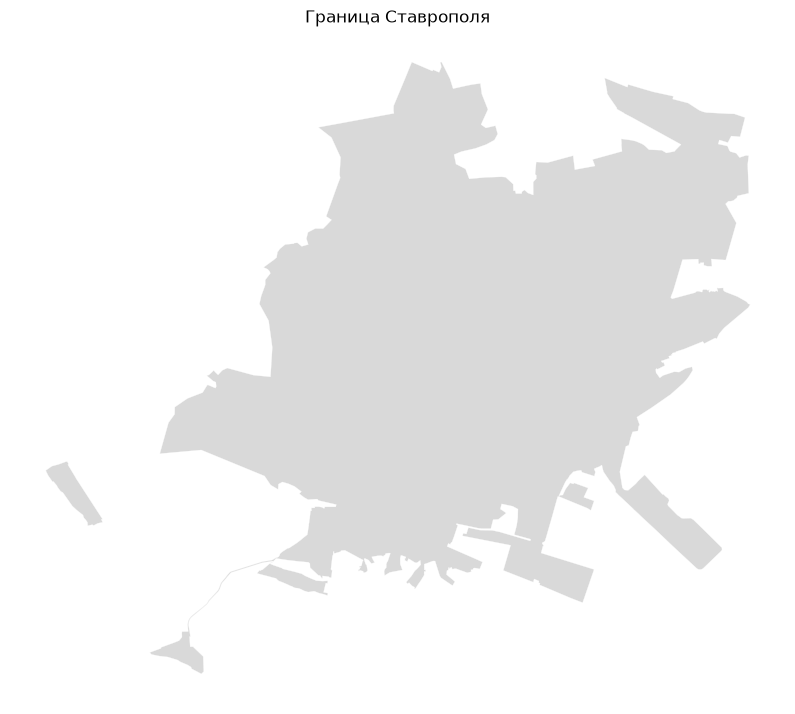

🖼️ Сохранена карта: prom_boundary_map.png


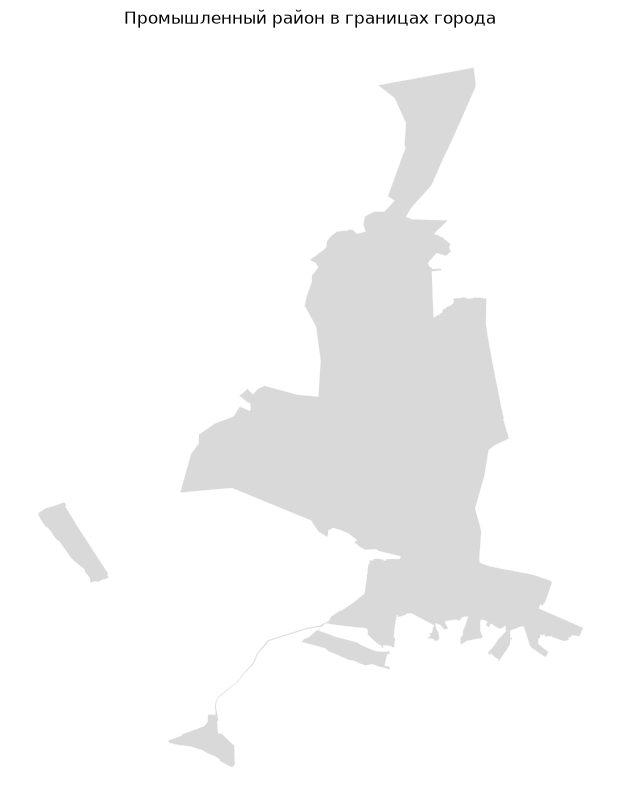

In [3]:
# ============================================================
# 1. ГРАНИЦЫ ТЕРРИТОРИИ
# ============================================================

def get_boundary(osm_id, path, name):
    if USE_CACHE and path.exists():
        gdf = load_geojson(path)
        print(f"📂 {name}: загружено из кэша")
    else:
        print(f"🌍 {name}: скачиваю границу из OpenStreetMap...")
        raw = ox.geocode_to_gdf(osm_id, by_osmid=True)
        gdf = gpd.GeoDataFrame(geometry=[raw.union_all()], crs=CRS_WGS84)
        save_geojson(gdf, path)
    return gdf.to_crs(CRS_METRIC)


city_boundary = get_boundary(CITY_OSM_ID, RAW_DIR / "boundaries_city.geojson", "Ставрополь")
prom_boundary_raw = get_boundary(PROM_OSM_ID, RAW_DIR / "boundaries_prom.geojson", "Промышленный район")

# Район может выходить за границу города — оставляем только часть внутри города.
city_geom = city_boundary.union_all()
prom_geom = prom_boundary_raw.union_all().intersection(city_geom).buffer(0)
if prom_geom.is_empty:
    raise ValueError("Промышленный район не пересекается с границей города. Проверьте OSM ID.")
prom_boundary = gpd.GeoDataFrame(geometry=[prom_geom], crs=CRS_METRIC)

print()
print(f"Площадь города: {city_boundary.area.sum() / 1e6:.1f} км²")
print(f"Площадь Промышленного района в границах города: {prom_boundary.area.sum() / 1e6:.1f} км²")

show_map(city_boundary, title="Граница Ставрополя", path=RESULTS_DIR / "city_boundary_map.png")
show_map(prom_boundary, title="Промышленный район в границах города", path=RESULTS_DIR / "prom_boundary_map.png")

## 2. Данные OpenStreetMap

Скачиваем шесть слоёв:

- дороги;
- железные дороги;
- вода;
- здания;
- функциональные зоны (`landuse`);
- школы (`amenity=school`).

**Источник:** OpenStreetMap, загрузка через Overpass API библиотекой OSMnx.
**Кэш:** каждый слой сохраняется в GeoJSON. Повторно из интернета не скачивается.

Если Overpass долго не отвечает, можно сменить сервер. Раскомментируйте строку
`ox.settings.overpass_url = ...` в следующей ячейке и запустите её снова.

In [4]:
# ============================================================
# 2. ДАННЫЕ OPENSTREETMAP
# ============================================================

ox.settings.use_cache = USE_CACHE
ox.settings.cache_folder = str(OSM_CACHE_DIR)
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

# Если основной сервер Overpass не отвечает, раскомментируйте одну из строк:
# ox.settings.overpass_url = "https://overpass.kumi.systems/api/interpreter"
# ox.settings.overpass_url = "https://overpass.private.coffee/api/interpreter"

bc_tags = {
    "roads": {
        "highway": [
            "construction", "crossing", "living_street", "motorway", "motorway_link",
            "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
            "residential", "road", "secondary", "secondary_link", "services",
            "tertiary", "tertiary_link", "track", "trunk", "trunk_link",
            "turning_circle", "turning_loop", "unclassified",
        ],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}


def fetch_osm(tags, path, name, keep_columns=None):
    """Скачивает объекты OSM по городу и кэширует их в GeoJSON."""
    if USE_CACHE and path.exists():
        gdf = load_geojson(path)
        print(f"📂 {name}: из кэша — {len(gdf)} объектов")
        return gdf

    print(f"🌍 {name}: скачиваю из OpenStreetMap (Overpass)...")
    polygon = city_boundary.to_crs(CRS_WGS84).union_all()
    gdf = ox.features_from_polygon(polygon, tags=tags).reset_index(drop=True)
    if keep_columns is not None:
        cols = [c for c in keep_columns if c in gdf.columns] + ["geometry"]
        gdf = gdf[cols].copy()
    save_geojson(gdf, path)
    return gdf.to_crs(CRS_METRIC)


print("Настройки OSMnx готовы.")

Настройки OSMnx готовы.


📂 Дороги: из кэша — 5126 объектов
📂 Железные дороги: из кэша — 102 объектов
📂 Вода: из кэша — 131 объектов

Дорог: 3473
Железных дорог: 102
Водных объектов: 131
🖼️ Сохранена карта: roads_map.png


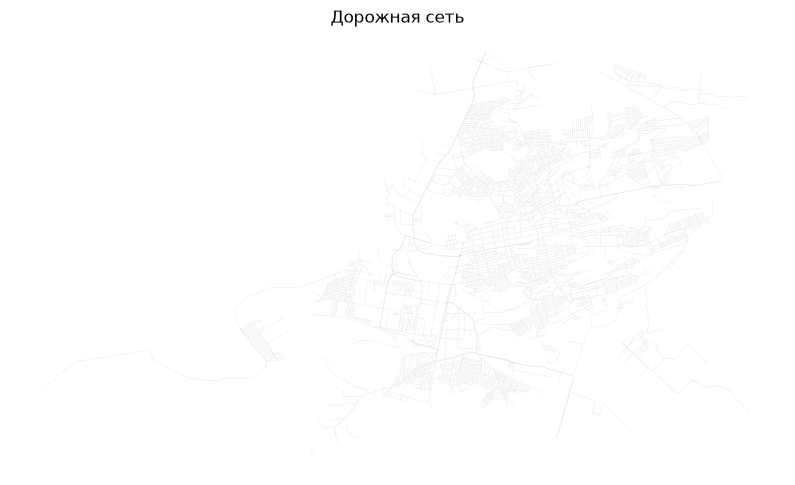

🖼️ Сохранена карта: water_map.png


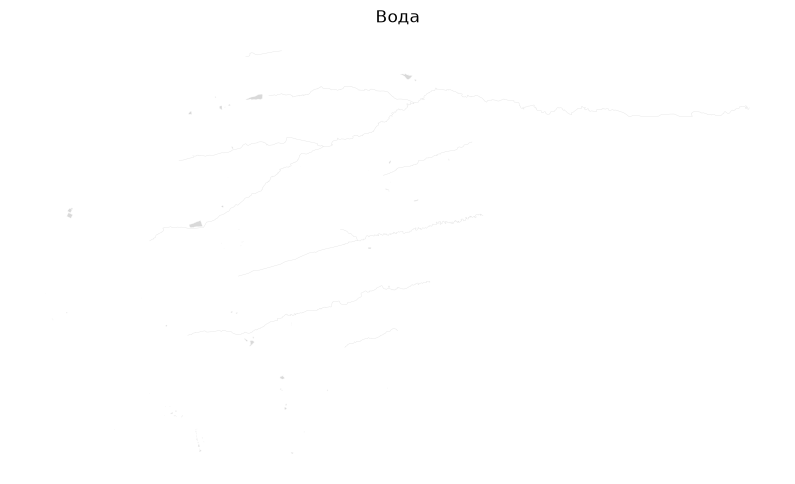

In [5]:
# Дороги, железные дороги и вода
roads = fetch_osm(bc_tags["roads"], RAW_DIR / "roads.geojson", "Дороги", keep_columns=["highway", "service"])
roads = roads[roads.geom_type.isin(["LineString", "MultiLineString"])].copy()

railways = fetch_osm(bc_tags["railways"], RAW_DIR / "railways.geojson", "Железные дороги", keep_columns=["railway"])
railways = railways[railways.geom_type.isin(["LineString", "MultiLineString"])].copy()

water = fetch_osm(bc_tags["water"], RAW_DIR / "water.geojson", "Вода", keep_columns=[])
water = water[water.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].copy()

print()
print("Дорог:", len(roads))
print("Железных дорог:", len(railways))
print("Водных объектов:", len(water))

show_map(roads, title="Дорожная сеть", path=RESULTS_DIR / "roads_map.png")
show_map(water, title="Вода", path=RESULTS_DIR / "water_map.png")

📂 Здания: из кэша — 57342 объектов
💾 Сохранено: buildings_clean.geojson — 57332 объектов

Зданий: 57332
Из них жилых (по тегу): 15.7%
С известной этажностью: 5.0%
🖼️ Сохранена карта: buildings_map.png


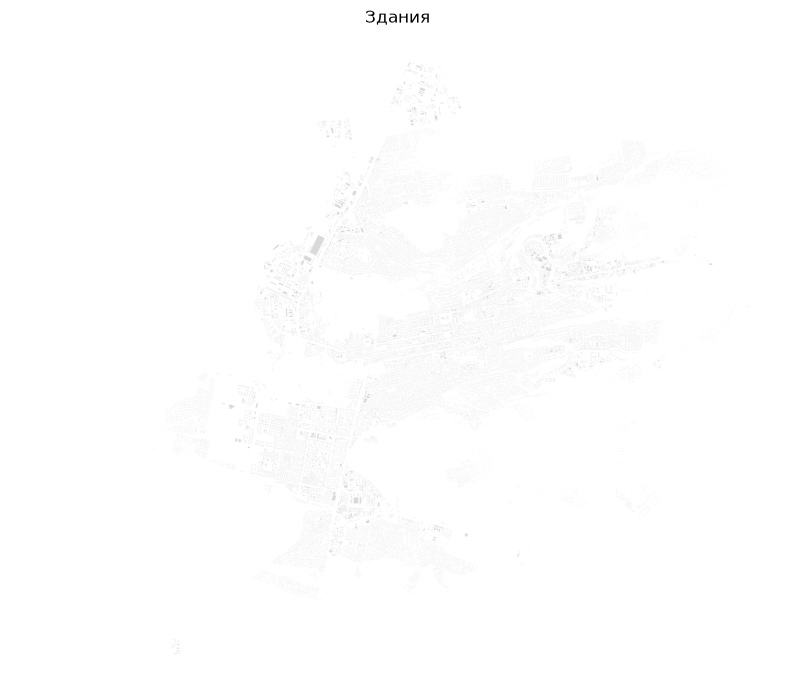

In [6]:
# Здания
buildings = fetch_osm(
    {"building": True},
    RAW_DIR / "buildings.geojson",
    "Здания",
    keep_columns=["building", "building:levels"],
)
buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
buildings["geometry"] = buildings.geometry.make_valid()
buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
buildings = buildings[buildings.geometry.notna() & ~buildings.geometry.is_empty].copy()

if len(buildings) == 0:
    raise RuntimeError("В OSM не найдено зданий. Проверьте интернет и границу города.")

living_tags = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
if "building" in buildings.columns:
    building_tag = buildings["building"].astype(str).str.lower().str.split(";").str[0].str.strip()
    buildings["is_living"] = building_tag.isin(living_tags)
    living_share = float(buildings["is_living"].mean())
    if FALLBACK_YES_AS_LIVING and living_share < MIN_LIVING_SHARE:
        fallback_mask = building_tag.isin(["yes", "true"])
        n_fallback = int(fallback_mask.sum())
        if n_fallback:
            buildings.loc[fallback_mask, "is_living"] = True
            print(
                "⚠️ Явных жилых тегов мало "
                f"({living_share:.1%}). Считаю building=yes жилыми: {n_fallback} зданий."
            )
            print("   Это допущение нужно указать в выводах.")
else:
    buildings["is_living"] = False

if "building:levels" in buildings.columns:
    levels = buildings["building:levels"].astype(str).str.split(";").str[0].str.strip()
    buildings["number_of_floors"] = pd.to_numeric(levels, errors="coerce")
else:
    buildings["number_of_floors"] = np.nan

buildings = buildings[["geometry", "is_living", "number_of_floors"]].copy()
save_geojson(buildings, RAW_DIR / "buildings_clean.geojson")

print()
print("Зданий:", len(buildings))
print(f"Из них жилых (по тегу): {buildings['is_living'].mean():.1%}")
print(f"С известной этажностью: {buildings['number_of_floors'].notna().mean():.1%}")
show_map(buildings, title="Здания", path=RESULTS_DIR / "buildings_map.png")

📂 Функциональные зоны: из кэша — 2731 объектов
💾 Сохранено: functional_zones_clean.geojson — 2729 объектов

Функциональных зон: 2729
Самые частые типы:
functional_zone
grass           1118
residential      856
commercial       166
allotments       141
industrial       111
garages           97
retail            70
construction      41
flowerbed         36
farmland          29

Первые 5 зон (как в примере pipeline.ipynb):


,geometry,functional_zone
2,"POLYGON ((731721.237 4991183.553, 731723.04 49...",construction
3,"POLYGON ((741134.381 4986022.219, 741097.051 4...",farmland
4,"POLYGON ((728537.173 4984809.114, 728660.141 4...",allotments
5,"POLYGON ((731972.236 4984944.709, 731983.327 4...",allotments
6,"POLYGON ((731315.177 4984818.838, 731281.461 4...",allotments


🖼️ Сохранена карта: functional_zones_map.png


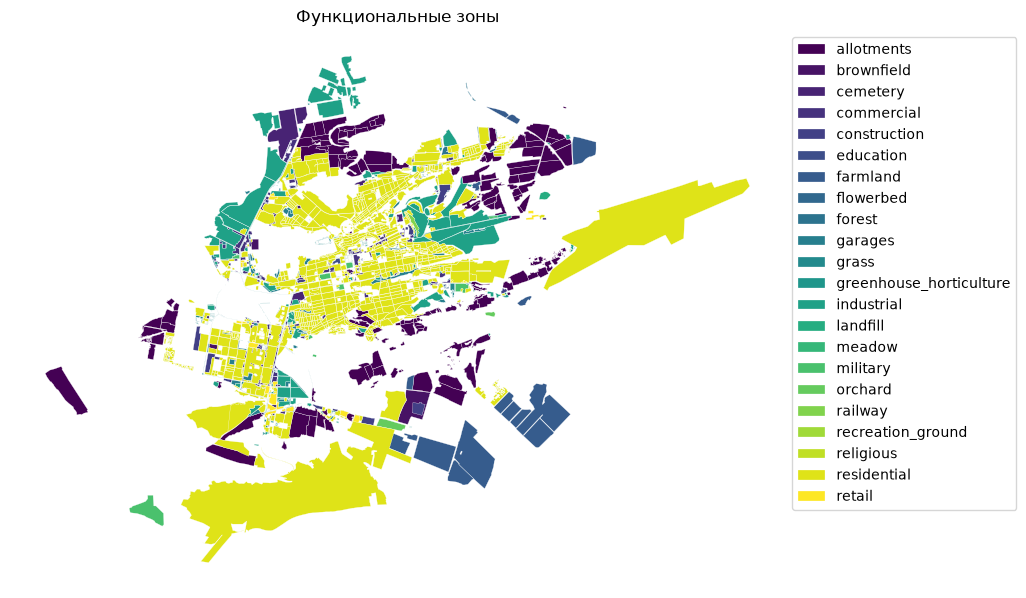

In [7]:
# Функциональные зоны
functional_zones = fetch_osm(
    {"landuse": True},
    RAW_DIR / "functional_zones.geojson",
    "Функциональные зоны",
    keep_columns=["landuse"],
)
functional_zones = functional_zones[
    functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()
functional_zones["geometry"] = functional_zones.geometry.make_valid()
functional_zones = functional_zones[
    functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()
functional_zones = functional_zones[
    functional_zones.geometry.notna() & ~functional_zones.geometry.is_empty
].copy()

if "landuse" not in functional_zones.columns:
    functional_zones["landuse"] = None
functional_zones = functional_zones[functional_zones["landuse"].notna()].copy()
functional_zones["functional_zone"] = functional_zones["landuse"].astype(str)
functional_zones = functional_zones[["geometry", "functional_zone"]].copy()
save_geojson(functional_zones, RAW_DIR / "functional_zones_clean.geojson")

print()
print("Функциональных зон:", len(functional_zones))
print("Самые частые типы:")
print(functional_zones["functional_zone"].value_counts().head(10).to_string())
print()
print("Первые 5 зон (как в примере pipeline.ipynb):")
display(functional_zones.head())
show_map(
    functional_zones,
    column="functional_zone",
    title="Функциональные зоны",
    categorical=True,
    path=RESULTS_DIR / "functional_zones_map.png",
)

📂 Школы: из кэша — 80 объектов


💾 Сохранено: schools_clean.geojson — 80 объектов

Школ: 80
С известной вместимостью: 1.2%
Суммарная известная вместимость: 1250
🖼️ Сохранена карта: schools_map.png


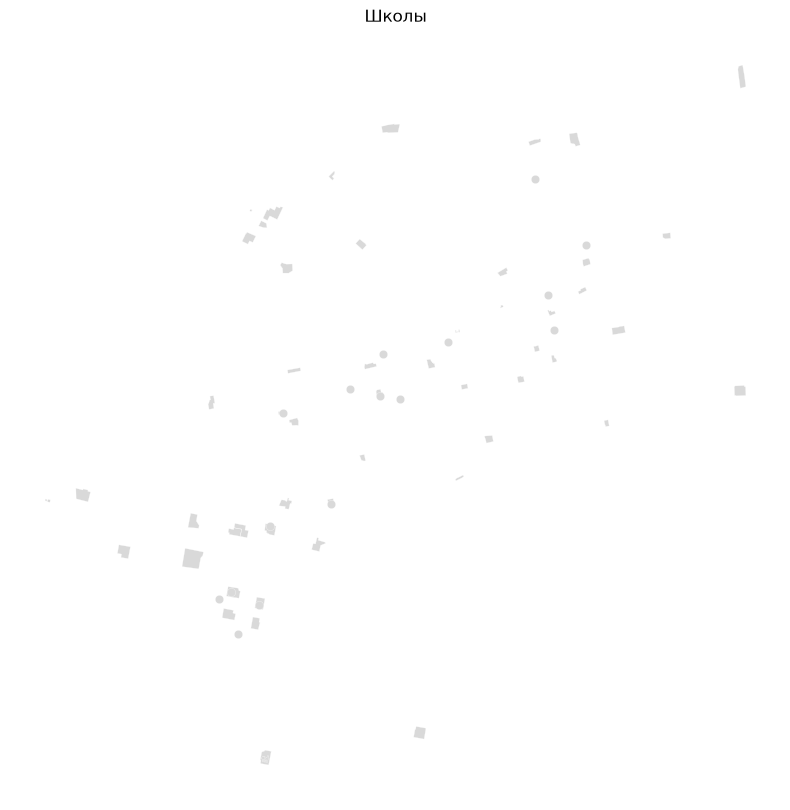

In [8]:
# Школы
schools = fetch_osm(
    {"amenity": "school"},
    RAW_DIR / "schools.geojson",
    "Школы",
    keep_columns=["amenity", "capacity"],
)
schools = schools[schools.geometry.notna() & ~schools.geometry.is_empty].copy()

if len(schools) == 0:
    raise RuntimeError("В OSM не найдено школ. Проверьте интернет и границу города.")

if "capacity" not in schools.columns:
    schools["capacity"] = np.nan
schools["capacity"] = pd.to_numeric(schools["capacity"], errors="coerce")
schools = schools[["geometry", "capacity"]].copy()
save_geojson(schools, RAW_DIR / "schools_clean.geojson")

print()
print("Школ:", len(schools))
print(f"С известной вместимостью: {schools['capacity'].notna().mean():.1%}")
print("Суммарная известная вместимость:", int(schools["capacity"].fillna(0).sum()))
show_map(schools, title="Школы", path=RESULTS_DIR / "schools_map.png")

## 3. Кварталы

Сначала режем **весь город**. Затем ноутбук смотрит, сколько получилось кварталов.

- Если не больше `MAX_BLOCKS` — работаем по городу.
- Если больше — переходим на **Промышленный район**.
- Если и район больше порога — берём **южную половину Промышленного района**
  (нижняя половина по координате Y, то есть южная часть).

Выбранная территория и число кварталов сохраняются в `data_stavropol/territory.json`.
Кварталы — в `data_stavropol/processed/<территория>_blocks.geojson`.

2026-10-31 15:04:35.928 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-31 15:04:35.940 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-31 15:04:35.945 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-31 15:04:35.958 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-31 15:04:35.963 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-31 15:04:35.979 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-10-31 15:04:35.988 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema
2026-10-31 15:04:35.988 

Линий для нарезки: 3624 | полигонов: 82
🧩 Весь город: 1846 кварталов, площадь 165.2 км²
💾 Сохранено: city_territory.geojson — 1 объектов
💾 Сохранено: city_blocks.geojson — 1846 объектов

✅ Территория в работе: весь город Ставрополь
   Кварталов: 1846
🖼️ Сохранена карта: city_blocks_map.png


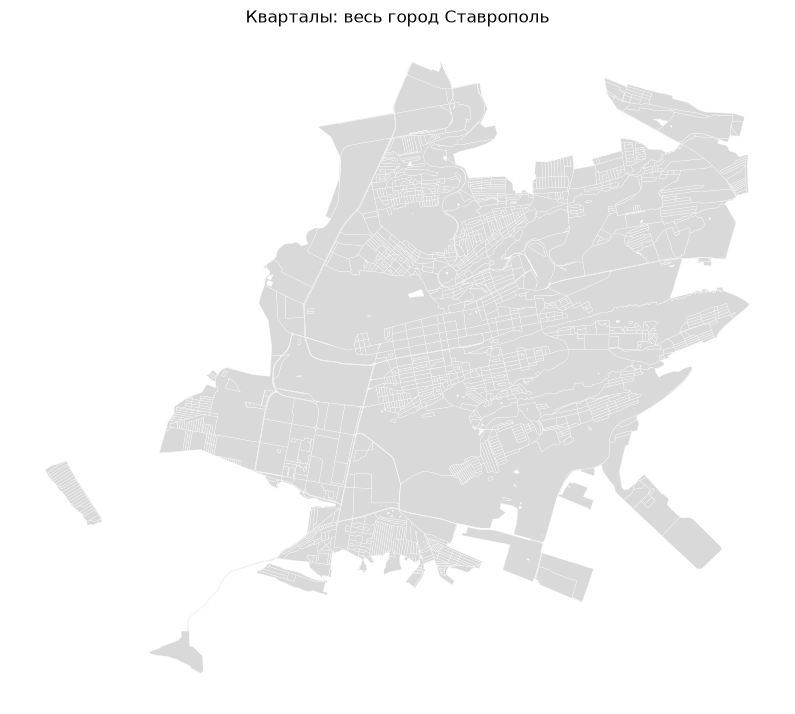

In [9]:
# ============================================================
# 3. КВАРТАЛЫ
# ============================================================

from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

roads = load_geojson(RAW_DIR / "roads.geojson")
railways = load_geojson(RAW_DIR / "railways.geojson")
water = load_geojson(RAW_DIR / "water.geojson")

# Исправляем возможные некорректные геометрии из OSM.
for _layer in (roads, railways, water):
    _layer["geometry"] = _layer.geometry.make_valid()

# В OSM по тегам highway/railway могут попасть точки и полигоны.
# Оставляем только линии для дорог и железных дорог; воде разрешены линии и полигоны.
roads = roads[roads.geom_type.isin(["LineString", "MultiLineString"])].copy()
railways = railways[railways.geom_type.isin(["LineString", "MultiLineString"])].copy()
water = water[
    water.geom_type.isin(["LineString", "MultiLineString", "Polygon", "MultiPolygon"])
].copy()

lines, polygons = preprocess_urban_objects(roads, railways, water)
lines = lines[lines.geometry.notna() & ~lines.geometry.is_empty].copy()
polygons = polygons[polygons.geometry.notna() & ~polygons.geometry.is_empty].copy()
print("Линий для нарезки:", len(lines), "| полигонов:", len(polygons))


def cut_blocks(boundary_gdf, name):
    blocks = cut_urban_blocks(boundary_gdf, lines, polygons)
    blocks = blocks[blocks.geometry.notna() & ~blocks.geometry.is_empty].copy()
    blocks = blocks.explode(index_parts=False).reset_index(drop=True)
    blocks = blocks[blocks.geom_type == "Polygon"].copy()
    blocks.index = pd.RangeIndex(len(blocks))
    blocks["site_area"] = blocks.area
    if len(blocks) == 0:
        raise ValueError(f"{name}: не удалось нарезать кварталы. Проверьте исходные слои.")
    print(f"🧩 {name}: {len(blocks)} кварталов, площадь {blocks.area.sum() / 1e6:.1f} км²")
    return blocks


try:
    city_blocks = cut_blocks(city_boundary, "Весь город")
except Exception as error:
    city_blocks = None
    print()
    print("⚠️ Не удалось нарезать весь город:", error)

n_city_blocks = None if city_blocks is None else len(city_blocks)

if TERRITORY_MODE == "city":
    if city_blocks is None:
        raise RuntimeError(
            "Не удалось нарезать город. Поставьте TERRITORY_MODE='prom' или 'auto'."
        )
    territory_key = "city"
elif TERRITORY_MODE == "prom":
    territory_key = "prom"
elif TERRITORY_MODE == "prom_south":
    territory_key = "prom_south"
elif TERRITORY_MODE == "auto":
    territory_key = "city"
    if city_blocks is None or n_city_blocks > MAX_BLOCKS:
        if n_city_blocks is not None:
            print()
            print(f"⚠️ В городе {n_city_blocks} кварталов — больше порога {MAX_BLOCKS}.")
            print("   Переключаюсь на Промышленный район.")
        territory_key = "prom"
else:
    raise ValueError("TERRITORY_MODE должен быть: auto, city, prom или prom_south")

if territory_key == "city":
    territory_boundary = city_boundary
    blocks = city_blocks
elif territory_key == "prom":
    territory_boundary = prom_boundary
    blocks = cut_blocks(prom_boundary, "Промышленный район")
else:  # prom_south
    territory_boundary = southern_half(prom_boundary)
    blocks = cut_blocks(territory_boundary, "Южная половина Промышленного района")

# Если и район слишком большой — берём его южную половину.
if (
    TERRITORY_MODE in ("auto", "prom")
    and territory_key == "prom"
    and ALLOW_PROM_SOUTH
    and len(blocks) > MAX_BLOCKS
):
    print()
    print(f"⚠️ В районе {len(blocks)} кварталов — больше порога {MAX_BLOCKS}.")
    print("   Беру южную половину Промышленного района.")
    territory_key = "prom_south"
    territory_boundary = southern_half(prom_boundary)
    blocks = cut_blocks(territory_boundary, "Южная половина Промышленного района")

territory_boundary = gpd.GeoDataFrame(geometry=[territory_boundary.union_all()], crs=CRS_METRIC)
save_geojson(territory_boundary, RAW_DIR / f"{territory_key}_territory.geojson")
save_geojson(blocks, PROCESSED_DIR / f"{territory_key}_blocks.geojson", with_block_id=True)

with open(DATA_DIR / "territory.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "territory_key": territory_key,
            "territory_name": TERRITORY_NAMES[territory_key],
            "mode": TERRITORY_MODE,
            "n_blocks": len(blocks),
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print()
print("✅ Территория в работе:", TERRITORY_NAMES[territory_key])
print("   Кварталов:", len(blocks))
show_map(
    blocks,
    title=f"Кварталы: {TERRITORY_NAMES[territory_key]}",
    path=RESULTS_DIR / f"{territory_key}_blocks_map.png",
)

---

# ⛔ ОСТАНОВКА

Кварталы готовы. **Дальше начинаются расчёты показателей.**

Пожалуйста, не запускайте следующие ячейки, пока не напишете в чат вопрос:

> «Какие метрики доступны и что они значат?»

Я объясню, что считается, какие данные нужны и что означают числа. После этого можно продолжать.

**Справочник метрик уже добавлен ниже — это разделы 3.5 и 3.6.** Их можно читать прямо сейчас, они ничего не запускают.

Если вы уже обсудили метрики — запустите следующую ячейку и идите дальше по порядку.

In [10]:
print("=" * 72)
print("⛔ ОСТАНОВКА: кварталы готовы, расчёты ещё не запущены.")
print("=" * 72)
print("Напишите в чат: «Какие метрики доступны и что они значат?»")
print("После обсуждения запускайте следующие ячейки по порядку.")
print()
print("Что уже сохранено:")
print("  •", PROCESSED_DIR / f"{territory_key}_blocks.geojson")
print("  •", RAW_DIR / f"{territory_key}_territory.geojson")
print("  •", DATA_DIR / "territory.json")

⛔ ОСТАНОВКА: кварталы готовы, расчёты ещё не запущены.
Напишите в чат: «Какие метрики доступны и что они значат?»
После обсуждения запускайте следующие ячейки по порядку.

Что уже сохранено:
  • c:\Users\Влада\.vscode\python-package-boilerplate\data_stavropol\processed\city_blocks.geojson
  • c:\Users\Влада\.vscode\python-package-boilerplate\data_stavropol\raw\city_territory.geojson
  • c:\Users\Влада\.vscode\python-package-boilerplate\data_stavropol\territory.json


## 3.5. Справочник метрик: что умеет BlocksNet и что считается в этом ноутбуке

> Этот раздел **ничего не считает** и ничего не скачивает. Это шпаргалка, чтобы вы понимали
> числа, которые появятся дальше. Читайте её спокойно, можно по частям.

### Самое главное

BlocksNet считает показатели не «по городу вообще», а по **кварталам** — небольшим участкам,
ограниченным дорогами, железными дорогами и водой. У каждого квартала есть площадь, здания,
население и время пути до других кварталов. Из этого получаются четыре большие группы чисел:

- **сколько построено** — площади, этажность, плотность;
- **кто живёт и чем пользуется** — население, школы, обеспеченность;
- **как быстро дойти** — пешеходный граф, время, доступность;
- **какой это тип застройки** — морфотипы.

### Три уровня, на которых считаются метрики

| Уровень | Что это | Примеры |
|---|---|---|
| Объект | одно здание, школа, полигон земли | площадь здания, этажность, вместимость школы |
| Квартал | участок между дорогами | население квартала, FSI, обеспеченность школами |
| Территория | весь город или район | медианная плотность, доля кварталов без школ, средняя доступность |

В ноутбуке почти всё считается **по кварталам**, а итог по территории — это медиана или сумма
по кварталам. Поэтому «средний FSI по городу» — это медиана FSI по кварталам, а не одно
большое число, посчитанное для всего города.

### В каких единицах бывают числа

| Единица | Что означает | Пример |
|---|---|---|
| м² | площадь | 12 500 м² |
| м²/м² | сколько квадратных метров чего-то приходится на 1 м² квартала или пола | FSI = 1,8 |
| доля 0…1 | часть от целого | GSI = 0,35 |
| этаж | средняя этажность | L = 9 |
| человек | люди | население 4 200 |
| место | вместимость школы или спрос | 250 мест |
| минута | время пешком | 12,4 мин |
| штука | количество объектов | 3 школы |

**Важно:** долю можно умножить на 100 и получить проценты: `0,35 = 35 %`. А FSI в проценты
не переводится — это коэффициент. Если FSI = 2, это значит «на 1 м² земли приходится 2 м²
площади всех этажей», а не «200 %».

---

## Часть 1. Какие метрики есть в BlocksNet 1.0.0a9

Ниже — все основные группы, доступные в установленной версии. Не все они используются
в `pipeline.ipynb`; что именно попало в наш расчёт — в Части 2.

| Группа | Простыми словами | Примеры показателей | Единицы |
|---|---|---|---|
| Плотность и застройка | сколько этажей и зданий стоит на земле | `fsi`, `gsi`, `mxi`, `l`, `osr`, `share_living`, `share_non_living` | м²/м², доли, этажи |
| Морфотипы | какой это тип застройки | `cluster`, `morphotype` | номер кластера, категория |
| Обеспеченность услугами | хватает ли школ, садиков, поликлиник | `provision_strong`, `provision_weak`, `demand`, `capacity`, `load` | доли, места, люди |
| Доступность сети | сколько минут идти до других кварталов | `mean_accessibility`, `median_accessibility`, `area_accessibility`, `connectivity` | минуты, 1/мин |
| Матрица поездок | кто куда едет | `origin_destination_matrix`, `road_congestion` | условные поездки |
| Разнообразие услуг | насколько услуги разные | `shannon_diversity` | безразмерный |
| Услуги | сколько объектов и как плотно они стоят | `services_count`, `services_density`, `services_collocation` | штуки, 1/м², доля |
| Землепользование | как используется земля | `calculate_land_use_shares`, `land_use_collocation`, `land_use_similarity` | доли, м², люди |
| Центральность | где находится «центр» | `population_centrality`, `services_centrality` | 0…1 |
| Геометрия | какая форма у квартала | `area`, `length`, `aspect_ratio`, `outer_radius`, `inner_radius` | м², м, коэффициент |
| Пустующие территории | где внутри кварталов есть свободная земля | `area`, `length`, `area_to_mrr_area` | м², м, доля |
| Социально-экономические | статистика территории | население, плотность, бюджет, зарплата, дорожная сеть | люди/км², км/км², рубли |

### Полный список функций по группам

| Модуль | Функции |
|---|---|
| `analysis.indicators` | `calculate_density_indicators`, `calculate_development_indicators` |
| `analysis.morphotypes` | `get_spacematrix_morphotypes`, `get_strelka_morphotypes` |
| `analysis.provision` | `competitive_provision`, `shared_provision`, `provision_strong_total`, `provision_weak_total` |
| `analysis.network.accessibility` | `mean_accessibility`, `median_accessibility`, `max_accessibility`, `area_accessibility`, `relative_accessibility`, `land_use_accessibility`, `land_use_accessibility_matrix` |
| `analysis.network.connectivity` | `calculate_connectivity` |
| `analysis.network.origin_destination` | `origin_destination_matrix` |
| `analysis.network.road_congestion` | `road_congestion` |
| `analysis.diversity` | `shannon_diversity` |
| `analysis.services` | `services_count`, `services_density`, `services_collocation` |
| `analysis.land_use` | `calculate_land_use_shares`, `calculate_land_use_indicators`, `land_use_collocation`, `land_use_similarity` |
| `analysis.centrality` | `population_centrality`, `services_centrality` |
| `analysis.geometry` | `calculate_area_length`, `calculate_aspect_ratio`, `calculate_centroids`, `calculate_radiuses`, `calculate_centerlines` |
| `analysis.vacant_area` | `get_vacant_areas` |
| `analysis.indicators.socio_economic` | `calculate_general_indicators`, `calculate_demographic_indicators`, `calculate_social_indicators`, `calculate_transport_indicators`, `calculate_engineering_indicators` |

### Что важно понимать про эти группы

- **Плотность и застройка** — самый универсальный блок. Он работает, если у кварталов есть
  площади зданий и этажность.
- **Морфотипы** — это не норматив, а описание. «Советский микрорайон» — не оценка «плохо»,
  а тип рисунка застройки.
- **Обеспеченность** бывает двух видов. `competitive_provision` учитывает конкуренцию
  кварталов за места и даёт `provision_strong` и `provision_weak`. `shared_provision` проще:
  делит вместимость в радиусе на население и даёт `provision` и `load`.
- **Доступность** измеряется в минутах. `area_accessibility` — средневзвешенное время
  до всех кварталов, а не до ближайшей школы.
- **Матрица поездок** и **загруженность дорог** — условные модельные величины. Их можно
  сравнивать между кварталами, но нельзя читать как «столько-то реальных машин».
- **Разнообразие услуг** (индекс Шеннона) показывает, насколько разные услуги есть в квартале.
  Ноль — только один тип услуг, чем больше — тем разнообразнее.
- **Землепользование** отвечает на вопрос «что здесь за земля»: жильё, бизнес,
  промышленность, рекреация, транспорт, специальное, сельское хозяйство.
- **Центральность** — рейтинг 0…1. Чем выше, тем больше квартал похож на центр:
  много людей, услуг, хорошие связи с соседями.
- **Геометрия** помогает понять, квартал компактный или вытянутый, большой или маленький.
  Это влияет на то, как читать плотность и доступность.
- **Пустующие территории** ищут свободные участки внутри кварталов. Полезно для разговора
  о том, где город может уплотняться без нового выхода за границы.
- **Социально-экономические показатели** считаются не по кварталам, а по поселению или
  территории, и требуют внешних официальных данных. В этом ноутбуке они не используются.

---

## Часть 2. Все показатели из `pipeline.ipynb`

Официальный пример `pipeline.ipynb` проходит такой путь: границы → кварталы →
землепользование → граф → матрица времени → здания и население → школы → обеспеченность →
плотность → морфотипы → доступность территории.

**Отличие нашего ноутбука:** в примере строится интермодальный граф (пешком плюс транспорт),
а у нас — только пешеходный, со скоростью 5 км/ч. Поэтому наши минуты — это время пешком,
и сравнивать их с числами из примера нельзя. Внутри нашего города сравнивать кварталы можно.

### 2.1. Квартал и землепользование

| Показатель | Единица | Что это простыми словами | Что покажет о Ставрополе |
|---|---|---|---|
| `site_area` | м² | площадь квартала по границам дорог, воды и железных дорог | какие кварталы большие, а какие мелкие; где нарезка дала гигантские промышленные участки |
| `land_use` | категория | преобладающий тип использования земли: жильё, бизнес, промышленность, рекреация, транспорт, специальное, сельское хозяйство | где в городе жилые массивы, где промзоны, где парки и пустыри |
| `share` | доля 0…1 | какая часть площади квартала покрыта выбранной зоной | насколько уверенно определён тип; `0,3` значит «зона покрывает только 30 % квартала» |
| `building_count` | штук | число зданий в квартале | где застройка густая по количеству объектов, а где стоят единичные большие здания |

**Про названия колонок.** В примере `pipeline.ipynb` число зданий называется `count`;
в нашем итоговом файле — `building_count`, чтобы не путать со школами.

### 2.2. Здания и население

| Показатель | Единица | Что это простыми словами | Что покажет о Ставрополе |
|---|---|---|---|
| `population` | человек | модельное население квартала: жилая площадь делится на 30 м² на человека | где живёт больше всего людей; сравнение районов по «весу» населения |
| `footprint_area` | м² | сумма площадей пятен застройки, то есть сколько земли занято зданиями | насколько плотно застроена земля, много ли свободных дворов |
| `build_floor_area` | м² | сумма площадей всех этажей всех зданий | общий «объём» застройки; сколько квадратных метров помещений здесь есть |
| `living_area` | м² | жилая площадь: для жилых зданий берётся 90 % общей площади этажей | сколько в квартале именно жилья, а не офисов и складов |
| `non_living_area` | м² | нежилая площадь: общая минус жилая | где сосредоточены рабочие места, торговля, склады |

**Как считается население.** Для каждого жилого здания: площадь этажей × 0,9 = жилая площадь;
жилая площадь ÷ 30 = число жителей (но не меньше 1 человека на жилое здание). Потом всё
суммируется по кварталу. Это **учебная модель**, а не перепись: если в OSM не хватает
этажности или площадей, население будет приблизительным.

### 2.3. Школы и обеспеченность

| Показатель | Единица | Что это простыми словами | Что покажет о Ставрополе |
|---|---|---|---|
| `school_count` | штук | число школ в квартале | где школы есть, а где их нет совсем |
| `school_capacity` | мест | суммарная вместимость школ квартала | сколько детей квартал может принять в своих школах |
| `demand` | мест | нормативная потребность: население ÷ 1000 × 120, округлённое вверх | сколько школьных мест «положено» кварталу по нормативу |
| `provision_strong` | доля 0…1 | какая часть спроса закрыта местами **в пределах 15 минут пешком** | где дети могут дойти до школы, а где нет |
| `provision_weak` | доля 0…1 | какая часть спроса закрыта **всеми доступными местами**, включая далёкие | где школ хватает в принципе, но не рядом |
| `links` | таблица `source`, `target`, `value` | какие кварталы «прикреплены» к каким школам и сколько учеников | направления потоков: из каких кварталов дети идут в какие школы |

**Про названия колонок.** В примере `pipeline.ipynb` вместимость называется `capacity`,
а число школ — `count`. В нашем итоговом файле это `school_capacity` и `school_count`,
чтобы не путать со зданиями.

**Что такое норматив.** В BlocksNet для школы задано: 120 мест на 1000 жителей и
доступность 15 минут. Если в квартале 1 000 жителей, ему нужно 120 мест. Если рядом
есть школа на 250 мест, она может закрыть спрос нескольких кварталов.

**Чего не хватает в данных.** Вместимость школ в OpenStreetMap почти всегда не указана.
`impute_services` ставит минимальную вместимость из конфига — 250 мест. Поэтому
`provision_strong` — это оценка при допущении «каждая школа на 250 мест», а не точный факт.

### 2.4. Плотностные показатели

| Показатель | Единица | Что это простыми словами | Что покажет о Ставрополе |
|---|---|---|---|
| `fsi` | м²/м² | коэффициент плотности застройки: вся площадь этажей ÷ площадь квартала | насколько интенсивно используется земля; где центр и новые микрорайоны, а где одноэтажная окраина |
| `gsi` | доля 0…1 | доля застроенной земли: пятно зданий ÷ площадь квартала | насколько квартал «закрыт» зданиями; где много дворов и зелени, а где сплошная застройка |
| `mxi` | доля 0…1 | доля жилья: жилая площадь ÷ вся площадь этажей | жилой это квартал, смешанный или почти нежилой |
| `l` | этажей | средняя этажность: вся площадь этажей ÷ пятно застройки | малоэтажная это окраина, среднеэтажный центр или многоэтажные новые районы |
| `osr` | м²/м² | открытые пространства: свободная площадь квартала ÷ площадь этажей | сколько открытой земли приходится на 1 м² помещений; где тесно, а где просторно |
| `share_living` | безразмерный | сколько в среднем этажей «жилой части» приходится на 1 м² пятна | насколько высоко поднимается именно жилая застройка |
| `share_non_living` | безразмерный | то же для нежилой части | насколько высоко поднимаются офисы, склады, торговля |

**Пример чтения.** Если FSI = 2, GSI = 0,4, L = 5, это значит: на 1 м² земли приходится
2 м² всех этажей, 40 % земли занято зданиями, а средняя этажность — 5. Если FSI высокий,
а GSI низкий, скорее всего, здания высокие и стоят свободно. Если оба высокие — застройка
плотная и многоэтажная.

### 2.5. Морфотипы застройки

| Показатель | Единица | Что это простыми словами | Что покажет о Ставрополе |
|---|---|---|---|
| `cluster` | номер | номер кластера Spacematrix: кварталы с похожими `l`, `fsi`, `mxi` собраны в группы | сколько разных типов застройки есть в городе и какие кварталы похожи друг на друга |
| `morphotype` (Spacematrix) | текст | описание кластера по трём осям: этажность, плотность, доля жилья | например, «mid-rise high-density residential» — среднеэтажный плотный жилой квартал |
| `morphotype` (Strelka) | текст | тип застройки по правилам: этажность плюс доля жилья и плотность | понятные категории вроде «советский микрорайон» или «индивидуальная застройка» |

**Spacematrix** по умолчанию делает 11 кластеров (в ноутбуке — не больше, чем кварталов
с застройкой). Название собирается из трёх частей:

- этажность: `low-rise`, `mid-rise`, `high-mid-rise`, `high-rise`, `tower`;
- плотность: `low-density`, `high-density`;
- доля жилья: `non-residential`, `mixed-use`, `residential`.

**Strelka** даёт один из 11 понятных типов:

| Тип | По-русски | Что означает |
|---|---|---|
| `low-rise non-residential` | малоэтажная нежилая | склады, гаражи, небольшие предприятия |
| `individual residential` | индивидуальное жильё | частные дома, низкая плотность |
| `low-rise model` | малоэтажная застройка | небольшие многоквартирные дома |
| `mid-rise` | среднеэтажная | обычная городская застройка 4–8 этажей |
| `mid-rise non-residential` | среднеэтажная нежилая | офисы, торговля, учреждения |
| `mid-rise microdistrict` | среднеэтажный микрорайон | свободная планировка, дворы, средняя плотность |
| `mid-rise block` | среднеэтажный квартал | плотная периметральная застройка |
| `mid-rise central model` | центральная модель | плотный центр с высокой долей жилья |
| `high-rise non-residential` | многоэтажная нежилая | высотные офисы, гостиницы |
| `high-rise soviet microdistrict` | советский микрорайон | многоэтажки с большими дворами |
| `high-rise modern microdistrict` | современный микрорайон | плотная новая многоэтажная застройка |

Морфотип — это **описание**, а не оценка. Он помогает увидеть структуру города: где частный
сектор, где советские микрорайоны, где новый плотный центр.

### 2.6. Доступность

| Показатель | Единица | Что это простыми словами | Что покажет о Ставрополе |
|---|---|---|---|
| матрица доступности | минуты | время пешком от центра каждого квартала до центра каждого другого квартала | какие части города связаны, а какие отрезаны; есть ли районы-«острова» |
| `area_accessibility` | минуты | средневзвешенное время от квартала до всех кварталов, где вес — площадь | насколько квартал удобно расположен относительно всего города; чем меньше, тем лучше |
| `area_accessibility_raw` | минуты | то же, но недостижимые пары остаются `inf` | честная картина, если в графе есть разрывы |
| `area_accessibility_cap60` | минуты | то же, но `inf` заменён на 60 минут | карта и сравнение районов, когда нужно одно число |

**Важно:** `area_accessibility` — это не «доступность школы» и не «15-минутный город».
Это среднее время до **всех** кварталов территории. Оно сильно зависит от размера
территории: у большого города значения будут больше, чем у маленького района.
Сравнивать имеет смысл кварталы внутри одной территории.

---

## Часть 3. Как читать числа: учебные ориентиры

Это **не нормативы** и не оценки «хорошо/плохо». Это подсказки, чтобы понять порядок чисел.

| Показатель | Низкое | Среднее | Высокое | Комментарий |
|---|---|---|---|---|
| `fsi` | меньше 0,5 | 0,5–1,5 | больше 1,5 | выше 3 — очень высокая плотность |
| `gsi` | меньше 0,15 | 0,15–0,35 | больше 0,35 | выше 0,5 — земля почти полностью занята зданиями |
| `l` | меньше 4 этажей | 4–8 этажей | 9 и больше | границы взяты из правил Strelka |
| `mxi` | меньше 0,2 | 0,2–0,5 | больше 0,5 | меньше 0,2 — почти нежилой квартал |
| `provision_strong` | меньше 0,5 | 0,5–0,8 | больше 0,8 | 1,0 — спрос закрыт полностью в 15 минутах |
| `area_accessibility` | меньше 10 мин | 10–20 мин | больше 20 мин | зависит от размера территории |
| `shannon_diversity` | 0 | 0,5–1,5 | больше 1,5 | 0 — только один тип услуг |
| `connectivity` | — | — | — | абсолютной шкалы нет, сравнивайте кварталы между собой |

---

## Часть 4. Чего нет в `pipeline.ipynb`, но можно добавить

- **Все услуги, а не только школы.** Детские сады, поликлиники, аптеки, магазины, спорт,
  культура. Тогда можно говорить о «15-минутном городе» не на одном примере.
- **Плотность и разнообразие услуг.** Сколько объектов на гектар и насколько они разные.
  Это покажет, где сервис сосредоточен, а где его почти нет.
- **Доли землепользования.** Какая часть города жилая, промышленная, рекреационная.
  Для Ставрополя с его промышленными зонами это особенно полезно.
- **Пустующие территории.** Где внутри кварталов есть свободная земля и сколько.
  Это разговор о внутреннем развитии без расширения границ.
- **Связность и центральность.** Какие кварталы являются «центрами притяжения»,
  а какие изолированы.
- **Геометрия кварталов.** Большие вытянутые кварталы и маленькие компактные
  по-разному влияют на пешую доступность.
- **Матрица поездок и загруженность дорог.** Условные потоки и нагрузка на улицы.
  Требует матрицы поездок и осторожной интерпретации.
- **Простая обеспеченность (`shared_provision`).** Альтернатива конкурентной модели:
  вместимость в радиусе делится на население.
- **Социально-экономические показатели.** Официальная статистика по территории:
  население, бюджет, зарплаты, дорожная сеть. Нужны внешние данные, которых нет в OSM.

Мы не добавляем всё сразу, потому что это увеличит время расчёта и усложнит разбор.
Но любой блок можно добавить отдельным разделом позже.

---

## Часть 5. Ограничения: что эти числа не говорят

- **OpenStreetMap неполный.** Если здание не отмечено или у него нет этажности, модель
  достроит его по правилам: 1 этаж, площадь по полигону.
- **Население — модель, а не перепись.** 30 м² жилой площади на человека — допущение.
  Оно может не совпадать с реальной плотностью проживания.
- **Школы — модель.** Вместимость 250 мест — допущение, потому что в OSM её почти нет.
- **Пешком 5 км/ч.** Мы не учитываем транспорт, светофоры, рельеф и закрытые проходы.
- **`inf` — это не ноль.** Это «дойти нельзя». При статистике такие пары надо считать
  отдельно, а не заменять нулём.
- **Границы кварталов зависят от дорог.** Если дорога не отмечена, квартал может получиться
  слишком большим, и все его показатели будут другими.
- **FSI и GSI чувствительны к нарезке.** Один и тот же дом в большом квартале даст
  меньшую плотность, чем в маленьком.
- **`provision_strong` — это доля спроса, а не число школ.** Значение 0,8 не значит
  «80 % школ»; это «80 % потребности в местах закрыто в 15 минутах».
- **`area_accessibility` — среднее до всех кварталов.** Оно не отвечает на вопрос
  «далеко ли до ближайшей школы».
- **Морфотипы — описание, а не качество.** «Советский микрорайон» не лучше и не хуже
  «современного микрорайона»; это разные типы.
- **Не сравнивайте абсолютные числа с официальной статистикой.** Модель нужна для
  сравнения кварталов и районов между собой, а не для отчёта «в городе живёт ровно столько».

---

## Часть 6. Что именно посчитает этот ноутбук

| Раздел | Что считается | Куда сохраняется |
|---|---|---|
| 4 | землепользование: `land_use`, `share` | `processed/<территория>_land_use.geojson` |
| 5 | пешеходный граф и матрица времени | `graph/*_walk_graph.pkl`, `results/*_accessibility_matrix.parquet` |
| 6 | здания, площади, население | `processed/*_buildings_blocks.geojson` |
| 7 | школы и их вместимость | `processed/*_schools_blocks.geojson` |
| 8 | спрос и обеспеченность школами | `results/*_provision.csv`, `*_provision_links.csv` |
| 9 | плотность: `fsi`, `gsi`, `mxi`, `l`, `osr` | `processed/*_density.csv` |
| 10 | морфотипы Spacematrix и Strelka | `processed/*_spacematrix.csv`, `*_strelka.csv` |
| 11 | доступность территории | `results/*_area_accessibility.csv` |
| 12 | итоговая таблица и карты | `results/*_blocks_final.geojson`, `*_metrics.csv` |

Дополнительно в итоговую таблицу попадут:

- `building_count` — число зданий в квартале;
- `school_count` — число школ;
- `spacematrix_cluster` — номер кластера Spacematrix;
- `spacematrix_morphotype` и `strelka_morphotype` — два взгляда на тип застройки;
- `area_accessibility_raw` и `area_accessibility_cap60` — два варианта доступности;
- `area_ha` — площадь квартала в гектарах.

---

## Часть 7. Мини-словарь

- **Квартал** — участок земли, ограниченный дорогами, водой и железными дорогами.
  В BlocksNet это основная единица расчёта.
- **OSM (OpenStreetMap)** — открытая карта, из которой берутся здания, дороги и услуги.
- **Overpass** — сервер, через который ноутбук скачивает слои OSM (дороги, здания, школы).
- **Geofabrik** — сайт с готовыми файлами OpenStreetMap по регионам. Из такого файла
  в разделе 5 собирается пешеходный граф.
- **Граф** — сеть дорог и тропинок, по которой считается время пути.
- **Матрица доступности** — таблица «откуда → куда → сколько минут».
- **`inf`** — «бесконечно», то есть дойти по графу нельзя.
- **Медиана** — число, которое делит ряд пополам: половина значений меньше, половина больше.
  Она устойчивее среднего, если есть выбросы.
- **Модельное население** — население, посчитанное по формуле, а не взятое из переписи.
- **Норматив** — правило «сколько мест положено на 1000 жителей».
- **FSI** — сколько квадратных метров этажей приходится на 1 м² квартала.
- **GSI** — какая доля земли занята зданиями.
- **MXI** — какая доля площади этажей является жилой.
- **L** — средняя этажность.
- **OSR** — сколько открытой земли приходится на 1 м² этажей.
- **Морфотип** — описание типа застройки, например «советский микрорайон».
- **Обеспеченность** — какая часть потребности закрыта услугами.

---

Если после расчётов какое-то число непонятно — напишите мне его название и раздел.
Разберём на конкретном квартале, без формул.

## 3.6. Соответствие примеру `pipeline.ipynb`

Этот ноутбук повторяет все шаги официального примера `pipeline.ipynb` и дополнительно
показывает промежуточные таблицы. Ничего не пропущено: каждый расчёт из примера имеет
свою ячейку, а каждый результат — вывод на экран, карту или файл.

### Карта шагов

| Шаг в `pipeline.ipynb` | Что делает пример | Раздел этого ноутбука | Что увидите |
|---|---|---|---|
| 1. Границы | скачивает границы района | 1, 2 | карта границ, файлы `raw/boundaries_*` |
| 1.2–1.3. Кварталы | готовит линии и режет территорию | 3 | `processed/<территория>_blocks.geojson`, карта кварталов |
| 2. Землепользование | скачивает зоны и назначает `land_use` | 2, 4 | `functional_zones`, `land_use`, карта землепользования |
| 3.1. Граф | строит интермодальный граф | 5.1 | пешеходный граф `walk` из файла Geofabrik (не интермодальный) |
| 3.2. Матрица | считает время между кварталами | 5.2 | `acc_mx`, фрагмент 5×5, гистограмма |
| 4.1. Здания | скачивает здания из OSM | 2 (общий слой OSM) | `raw/buildings_clean.geojson` |
| 4.1.1. `is_living` | определяет жилые здания | 2 (очистка) | колонка `is_living` |
| 4.1.2. Этажность | читает `building:levels` | 2 (очистка) | колонка `number_of_floors` |
| 4.2. Пропуски | заполняет площади, этажи, население | 6 | таблица `buildings` после заполнения |
| 4.3. Агрегация | привязывает здания к кварталам | 6 | таблица `buildings_blocks`, карта населения |
| 5.1. Школы | скачивает школы из OSM | 2 (общий слой OSM) | `raw/schools_clean.geojson` |
| 5.2. Вместимость | заполняет пропуски вместимости | 7 | таблица `schools` после заполнения |
| 5.3. Агрегация | привязывает школы к кварталам | 7 | таблица `schools_blocks`, карта вместимости |
| 7.1. Обеспеченность | распределяет спрос на школы | 8 | `prov_input`, `prov_df`, `links_df`, карта |
| 7.2. Плотность | считает `fsi`, `gsi`, `mxi`, `l`, `osr` | 9 | `density_df`, медианы, карта и гистограмма FSI |
| 7.2.1. Spacematrix | кластеризует кварталы | 10 | `spacematrix_df`, `spacematrix_clusters`, карта |
| 7.2.2. Strelka | присваивает понятные типы | 10 | `strelka_df`, карта, столбчатая диаграмма |
| 7.3. Доступность | считает `area_accessibility` | 11 | `area_df`, два варианта, карта |
| 6. Результаты | перечисляет полученные слои | 12 | итоговая таблица и `blocks_final.geojson` |

### Какие таблицы добавлены для проверки

В примере после каждого шага стоит `.head()` — «покажи первые пять строк». Это нужно,
чтобы глазами проверить, что расчёт дал ожидаемые колонки. Мы добавили такие же показы:

| Где | Что показывается | Зачем |
|---|---|---|
| 2 | `functional_zones.head()` | проверить, что у зон есть тип `functional_zone` |
| 4 | `land_use.head()` | проверить, что кварталам назначен `land_use` и доля `share` |
| 5.2 | фрагмент матрицы 5×5 | убедиться, что по диагонали `0`, а время похоже на минуты |
| 6 | `buildings.head()` | проверить, что появились `footprint_area`, `build_floor_area`, `population` |
| 6 | `buildings_blocks.head()` | проверить, что население и площади собрались по кварталам |
| 7 | `schools.head()` | проверить, что появилась колонка `capacity` |
| 7 | `schools_blocks.head()` | проверить, что школы привязались к кварталам |
| 8 | `prov_input.head()` | увидеть, какие данные вообще подаются в расчёт |
| 8 | `prov_df.head()` | проверить `demand`, `provision_strong`, `provision_weak` |
| 8 | `links_df.head()` | увидеть, из какого квартала сколько учеников ушло в какую школу |
| 9 | `density_df.head()` | проверить все плотностные колонки |
| 10 | `spacematrix_df.head()` | увидеть номер кластера и тип застройки |
| 10 | `spacematrix_clusters` | понять, чем кластеры отличаются по `l`, `fsi`, `mxi` |
| 10 | `strelka_df.head()` | увидеть понятный тип застройки |
| 12 | `final.head()` | проверить, что все показатели собрались в одну таблицу |

**Важно:** `.head()` показывает только первые строки, это не статистика. Выводы делаются
по медианам, картам и итоговой таблице, а не по пяти первым кварталам.

### Чего в примере нет, а у нас есть

- **Сохранение на диск.** Пример держит всё в памяти. У нас каждый шаг пишет GeoJSON,
  CSV или parquet, поэтому расчёт можно прервать и продолжить.
- **Кэш.** Повторный запуск не скачивает OSM и не строит граф заново.
- **Пешеходный граф вместо интермодального.** В примере пешком плюс транспорт, у нас
  только пешком, 5 км/ч. Поэтому минуты нельзя сравнивать с примером.
- **Два варианта доступности.** `area_accessibility_raw` (с `inf`) и
  `area_accessibility_cap60` (для карты).
- **Итоговая таблица.** Все показатели в одном файле — его будет читать HTML-дашборд.

## 4. Землепользование кварталов

Берём полигоны `landuse` из OpenStreetMap и правилами переводим их в типы BlocksNet:
жильё, бизнес, промышленность, рекреация, транспорт, специальное, сельское хозяйство.

Если квартал не покрыт ни одной зоной, тип останется пустым (`None`). Это честнее, чем
придумывать назначение. В выводе будет видно, для какой доли кварталов тип определён.

Результат: `data_stavropol/processed/<территория>_land_use.geojson`.

💾 Сохранено: city_land_use.geojson — 1846 объектов

Тип использования определён для 78.1% кварталов.
Распределение:
land_use
residential    851
None           405
agriculture    398
recreation      99
industrial      46
business        32
special         10
transport        5

Первые 5 кварталов с назначением земли:


,geometry,land_use,share
0,"POLYGON ((735803.344 4993925.52, 735803.507 49...",industrial,0.622465
1,"POLYGON ((735805.465 4993968.093, 735804.611 4...",residential,0.499727
2,"POLYGON ((735805.465 4993968.093, 735805.328 4...",transport,0.537054
3,"POLYGON ((735805.328 4993972.226, 735805.465 4...",None,NaN
4,"POLYGON ((735805.328 4993972.226, 735808.21 49...",industrial,0.782399


🖼️ Сохранена карта: city_land_use_map.png


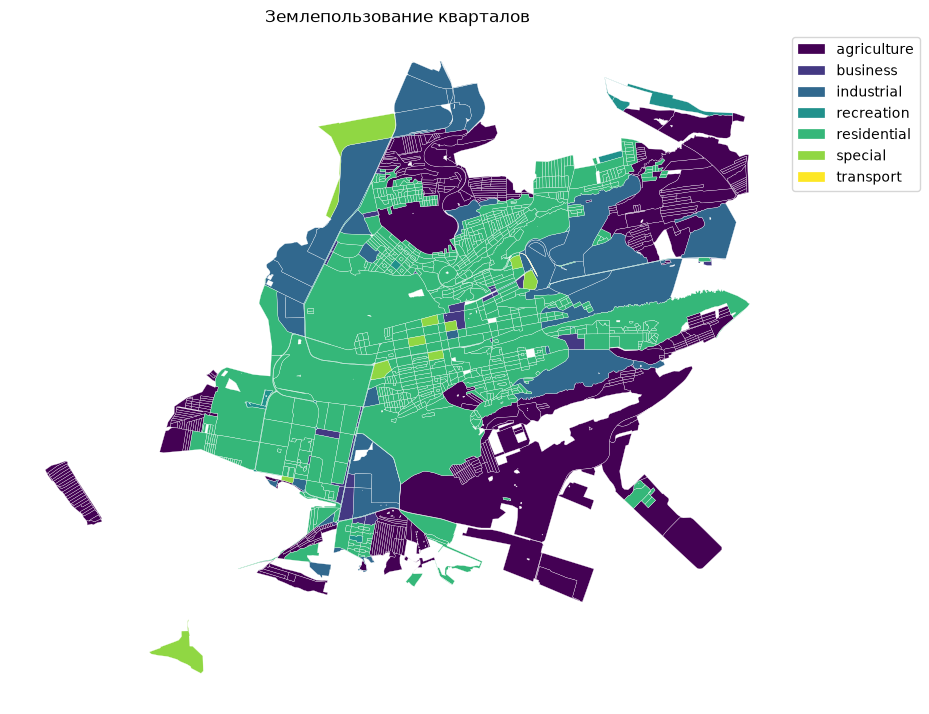

In [11]:
# ============================================================
# 4. ЗЕМЛЕПОЛЬЗОВАНИЕ
# ============================================================

from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

territory_key, territory_boundary, territory_meta = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)

functional_zones = load_geojson(RAW_DIR / "functional_zones_clean.geojson")
functional_zones = functional_zones[
    functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()
if len(functional_zones) == 0:
    raise RuntimeError("Нет функциональных зон. Проверьте файл functional_zones_clean.geojson.")

rules = {
    "residential": LandUse.RESIDENTIAL,
    "commercial": LandUse.BUSINESS,
    "retail": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "garages": LandUse.INDUSTRIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "landfill": LandUse.INDUSTRIAL,
    "quarry": LandUse.INDUSTRIAL,
    "construction": LandUse.SPECIAL,
    "cemetery": LandUse.SPECIAL,
    "religious": LandUse.SPECIAL,
    "military": LandUse.SPECIAL,
    "education": LandUse.SPECIAL,
    "institutional": LandUse.SPECIAL,
    "grass": LandUse.RECREATION,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "flowerbed": LandUse.RECREATION,
    "greenfield": LandUse.RECREATION,
    "meadow": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "orchard": LandUse.AGRICULTURE,
    "vineyard": LandUse.AGRICULTURE,
    "allotments": LandUse.AGRICULTURE,
    "greenhouse_horticulture": LandUse.AGRICULTURE,
    "aquaculture": LandUse.AGRICULTURE,
    "railway": LandUse.TRANSPORT,
    "port": LandUse.TRANSPORT,
    "transportation": LandUse.TRANSPORT,
    "highway": LandUse.TRANSPORT,
    "basin": LandUse.RECREATION,
    "reservoir": LandUse.RECREATION,
}

land_use = assign_land_use(blocks, functional_zones[["geometry", "functional_zone"]], rules)


def to_land_use_value(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    return getattr(value, "value", None)


land_use["land_use"] = land_use["land_use"].apply(to_land_use_value)
land_use = land_use[["geometry", "land_use", "share"]].copy()

save_geojson(land_use, PROCESSED_DIR / f"{territory_key}_land_use.geojson", with_block_id=True)

assigned = land_use["land_use"].notna().mean()
print()
print(f"Тип использования определён для {assigned:.1%} кварталов.")
print("Распределение:")
print(land_use["land_use"].value_counts(dropna=False).to_string())
print()
print("Первые 5 кварталов с назначением земли:")
display(land_use.head())
show_map(
    land_use,
    column="land_use",
    title="Землепользование кварталов",
    categorical=True,
    path=RESULTS_DIR / f"{territory_key}_land_use_map.png",
)

## 5. Пешеходный граф

**Что это.** Граф — это сеть улиц, по которым можно ходить. По ней ноутбук считает,
сколько минут идти от одного квартала до другого.

- **Источник данных:** OpenStreetMap.
- **Откуда берём:** официальный файл региона `.osm.pbf` с сайта Geofabrik
  (Северо-Кавказский федеральный округ, около 120 МБ). Скачивается **один раз**
  и остаётся на диске.
- **Способ передвижения:** пешком.
- **Скорость:** 5 км/ч (83,33 метра в минуту).
- **Время:** в минутах, поле `time_min`.
- **Что не делаем:** интермодальный граф (пешком плюс транспорт) не строим.

### Почему не через Overpass

Обычно BlocksNet берёт граф из Overpass API — того же сервера, откуда скачиваются
слои OSM. У вашего провайдера этот сервер не отвечает, поэтому мы берём **те же данные
OpenStreetMap**, только готовым файлом, и собираем граф на компьютере.
Результат тот же: улицы, длина в метрах, время в минутах.

### Что делает ячейка

1. Скачивает региональный файл OSM (~120 МБ). Если файл уже есть — пропускает.
2. Вырезает из него **только пешеходные улицы** вокруг выбранной территории.
3. Собирает граф, считает длину и время и сохраняет
   `data_stavropol/graph/<территория>_walk_graph.pkl`.

При первом запуске ячейка сама поставит маленький пакет `osmium` — он нужен,
чтобы прочитать файл OSM. Это одна команда установки, ничего настраивать не надо.

**Время:** первый раз 3–10 минут (сборка графа), потом секунды — граф
берётся из файла. **Место на диске:** около 150 МБ.

In [12]:
# ============================================================
# 5.1. ПЕШЕХОДНЫЙ ГРАФ
# ============================================================

import ctypes
import html
import importlib
import re
import subprocess
import sys
import time

import networkx as nx
import osmnx as ox
import requests
from iduedu.utils.utils import estimate_crs_for_bounds, remove_weakly_connected_nodes

try:
    import osmium
except ModuleNotFoundError:
    print("📦 Ставлю пакет osmium — он читает файл OpenStreetMap...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "osmium"])
    importlib.invalidate_caches()
    import osmium

ox.settings.log_console = False

# Готовый файл OpenStreetMap по Северному Кавказу (скачивается один раз)
OSM_PBF_URL = "https://download.geofabrik.de/russia/north-caucasus-fed-district-latest.osm.pbf"
OSM_PBF_PATH = GRAPH_DIR / "north-caucasus-fed-district-latest.osm.pbf"
EXTRACT_MARGIN_DEG = 0.02      # запас вокруг территории, примерно 2 км

# Улицы, по которым пешком не ходят (те же правила, что в OSMnx)
WALK_BLOCKED_HIGHWAY = re.compile(
    r"abandoned|bus_guideway|construction|cycleway|motor|no|planned|platform|"
    r"proposed|raceway|razed|rest_area|services"
)


def short_path(path):
    """Короткий путь Windows: библиотека osmium не понимает кириллицу в пути."""
    path = Path(path).resolve()
    if str(path).isascii():
        return str(path)
    buffer = ctypes.create_unicode_buffer(1024)
    if ctypes.windll.kernel32.GetShortPathNameW(str(path.parent), buffer, 1024) == 0:
        return str(path)
    return str(Path(buffer.value) / path.name)


def download_file(url, path):
    """Скачивает файл. Если файл уже есть — не скачивает заново."""
    if path.exists() and path.stat().st_size > 1024:
        print(f"   файл уже скачан: {path.name} ({path.stat().st_size / 1e6:.0f} МБ)")
        return path

    part = path.with_suffix(path.suffix + ".part")
    started = time.time()
    done, total, next_mark = 0, 0, 10

    with requests.get(url, stream=True, timeout=180) as response:
        response.raise_for_status()
        total = int(response.headers.get("Content-Length", 0))
        with open(part, "wb") as file:
            for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                file.write(chunk)
                done += len(chunk)
                if total and 100 * done / total >= next_mark:
                    print(f"   {next_mark}% — {done / 1e6:.0f} МБ из {total / 1e6:.0f} МБ")
                    next_mark += 10

    print(f"   скачано {done / 1e6:.0f} МБ за {time.time() - started:.0f} секунд")
    part.replace(path)
    return path


def is_walk_way(tags):
    """Годится ли улица для пешеходного графа (те же правила, что в OSMnx)."""
    highway = tags.get("highway")
    if highway is None or WALK_BLOCKED_HIGHWAY.search(highway):
        return False
    if "yes" in tags.get("area", ""):
        return False
    if "private" in tags.get("access", ""):
        return False
    if "private" in tags.get("service", ""):
        return False
    if "no" in tags.get("foot", ""):
        return False
    for key in ("sidewalk", "sidewalk:both", "sidewalk:left", "sidewalk:right"):
        if "separate" in tags.get(key, ""):
            return False
    return True


def extract_walk_osm(pbf_path, out_path, bounds, margin_deg=EXTRACT_MARGIN_DEG):
    """Оставляет из большого файла OSM только пешеходные улицы вокруг территории."""
    left, bottom, right, top = bounds
    left, bottom = left - margin_deg, bottom - margin_deg
    right, top = right + margin_deg, top + margin_deg

    nodes = {}
    ways = []

    for item in osmium.FileProcessor(short_path(pbf_path)).with_filter(
        osmium.filter.EntityFilter(osmium.osm.NODE | osmium.osm.WAY)
    ):
        if isinstance(item, osmium.osm.Node):
            location = item.location
            if (
                location.valid()
                and left <= location.lon <= right
                and bottom <= location.lat <= top
            ):
                nodes[item.id] = (location.lat, location.lon)
            continue

        tags = {tag.k: tag.v for tag in item.tags}
        if not is_walk_way(tags):
            continue
        refs = [node.ref for node in item.nodes]
        if len(refs) < 2 or any(ref not in nodes for ref in refs):
            continue
        ways.append((item.id, refs, tags))

    used_nodes = {ref for _, refs, _ in ways for ref in refs}

    with open(out_path, "w", encoding="utf-8", newline="\n") as file:
        file.write('<?xml version="1.0" encoding="UTF-8"?>\n')
        file.write('<osm version="0.6" generator="stavropol-notebook">\n')
        for node_id in used_nodes:
            lat, lon = nodes[node_id]
            file.write(f'  <node id="{node_id}" lat="{lat:.7f}" lon="{lon:.7f}"/>\n')
        for way_id, refs, tags in ways:
            file.write(f'  <way id="{way_id}">\n')
            for ref in refs:
                file.write(f'    <nd ref="{ref}"/>\n')
            for key, value in tags.items():
                file.write(
                    f'    <tag k="{html.escape(key, quote=True)}" '
                    f'v="{html.escape(value, quote=True)}"/>\n'
                )
            file.write("  </way>\n")
        file.write("</osm>\n")

    print(
        f"   узлов: {len(used_nodes):,} | пешеходных улиц: {len(ways):,}".replace(",", " ")
    )
    return out_path

def finalize_walk_graph(graph, walk_speed, local_crs):
    """Переводит граф в метры и считает длину и время каждой линии."""
    nodes, edges = ox.graph_to_gdfs(graph)
    nodes = nodes.to_crs(local_crs)
    nodes[["x", "y"]] = nodes.apply(
        lambda row: (row.geometry.x, row.geometry.y), axis=1, result_type="expand"
    )
    nodes = nodes[["x", "y", "geometry"]]

    edges = edges.reset_index().to_crs(local_crs)
    edges["length_meter"] = edges.geometry.length.round(3)
    edges["time_min"] = (edges.geometry.length / walk_speed).round(3)
    edges["type"] = "walk"
    edges = edges[
        ["u", "v", "key", "length_meter", "time_min", "type", "geometry"]
    ].set_index(["u", "v", "key"])

    graph = ox.graph_from_gdfs(nodes, edges)
    graph = remove_weakly_connected_nodes(graph)
    mapping = {old_label: new_label for new_label, old_label in enumerate(graph.nodes())}
    graph = nx.relabel_nodes(graph, mapping)
    graph.graph["crs"] = local_crs
    graph.graph["walk_speed"] = walk_speed
    graph.graph["type"] = "walk"
    return graph


territory_key, territory_boundary, territory_meta = get_territory()
graph_path = GRAPH_DIR / f"{territory_key}_walk_graph.pkl"

if USE_CACHE and graph_path.exists():
    graph = load_graph(graph_path)
    print(f"📂 Граф загружен из кэша: {graph_path.name}")
else:
    bounds = tuple(territory_boundary.to_crs(CRS_WGS84).total_bounds)

    print("1/3. Скачиваю файл OpenStreetMap (~120 МБ, только в первый раз)...")
    download_file(OSM_PBF_URL, OSM_PBF_PATH)

    print("2/3. Вырезаю пешеходные улицы вокруг территории...")
    walk_osm = GRAPH_DIR / f"{territory_key}_walk.osm"
    extract_walk_osm(OSM_PBF_PATH, walk_osm, bounds)

    print("3/3. Собираю граф и считаю время...")
    raw_graph = ox.graph_from_xml(
        walk_osm, bidirectional=True, simplify=True, retain_all=False
    )
    local_crs = estimate_crs_for_bounds(*bounds).to_epsg()
    graph = finalize_walk_graph(raw_graph, WALK_SPEED_M_PER_MIN, local_crs)

    save_graph(graph, graph_path)
    print(f"💾 Граф сохранён: {graph_path.name}")

if graph.number_of_edges() == 0:
    raise ValueError(
        "В графе нет рёбер. Проверьте границы территории и файл "
        f"{OSM_PBF_PATH.name}."
    )

edge_data = next(iter(graph.edges(data=True)))[2]
if GRAPH_WEIGHT not in edge_data:
    raise ValueError(f"В графе нет веса {GRAPH_WEIGHT}")

total_km = sum(data["length_meter"] for _, _, data in graph.edges(data=True)) / 1000

print()
print("Узлов:", graph.number_of_nodes(), "| рёбер:", graph.number_of_edges())
print(f"Общая длина пешеходных улиц в графе: {total_km:.0f} км")
print("Источник: OpenStreetMap (региональный файл Geofabrik).")
print("Способ передвижения: пешком, 5 км/ч. Время — в минутах.")

📂 Граф загружен из кэша: city_walk_graph.pkl

Узлов: 27977 | рёбер: 78896
Общая длина пешеходных улиц в графе: 7361 км
Источник: OpenStreetMap (региональный файл Geofabrik).
Способ передвижения: пешком, 5 км/ч. Время — в минутах.


### 5.2. Матрица времени между кварталами

Матрица показывает, сколько минут идти от центра одного квартала до центра другого.
Строки и столбцы — номера кварталов (`block_id`).

- Значение `0` — тот же квартал.
- Число — время в минутах.
- `inf` — дойти по графу нельзя (например, квартал отрезан или граф разорван).

Матрица сохраняется в `data_stavropol/results/<территория>_accessibility_matrix.parquet`
в формате `float32`, чтобы не занимать лишнюю память.

📂 Матрица загружена из кэша: city_accessibility_matrix.parquet
Размер матрицы: (1846, 1846)

Кварталов: 1846
Пар кварталов: 3 405 870
Достижимо: 3 405 870 (100.0%)
Недостижимо (inf): 0
Медианное время: 100.9 мин
Доля пар до 15 минут: 1.6%
Доля пар до 30 минут: 5.8%

Фрагмент матрицы 5×5 (строки — откуда, столбцы — куда, минуты):


,0,1,2,3,4
0,0.000000,37.200001,33.0,37.900002,37.700001
1,37.200001,0.000000,14.5,0.000000,5.500000
2,33.000000,14.500000,0.0,15.200000,11.600000
3,37.900002,0.000000,15.2,0.000000,6.200000
4,37.700001,5.500000,11.6,6.200000,0.000000


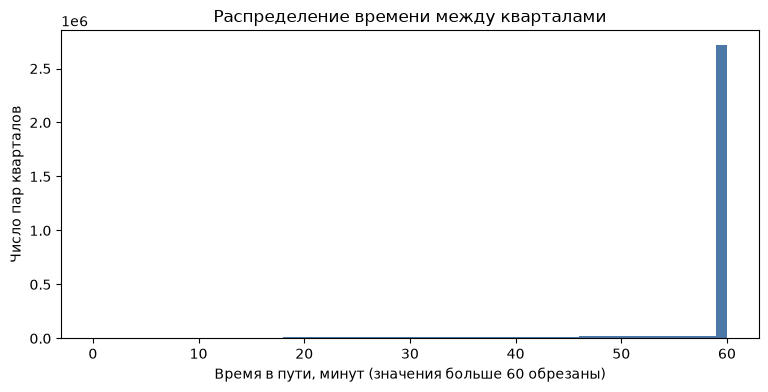

In [13]:
# ============================================================
# 5.2. МАТРИЦА ДОСТУПНОСТИ
# ============================================================

from blocksnet.relations import calculate_accessibility_matrix

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)

if "graph" not in globals():
    graph = load_graph(GRAPH_DIR / f"{territory_key}_walk_graph.pkl")

matrix_path = RESULTS_DIR / f"{territory_key}_accessibility_matrix.parquet"

if USE_CACHE and matrix_path.exists():
    acc_mx = pd.read_parquet(matrix_path)
    print(f"📂 Матрица загружена из кэша: {matrix_path.name}")
else:
    print("⏳ Считаю матрицу времени между кварталами...")
    acc_mx = calculate_accessibility_matrix(
        blocks,
        graph,
        weight_key=GRAPH_WEIGHT,
        dtype=MATRIX_DTYPE,
        max_workers=MAX_WORKERS,
    )
    acc_mx.to_parquet(matrix_path)
    print(f"💾 Матрица сохранена: {matrix_path.name}")

print("Размер матрицы:", acc_mx.shape)
if set(acc_mx.index) != set(blocks.index) or set(acc_mx.columns) != set(blocks.index):
    print("⚠️ Индексы матрицы и кварталов не совпадают. Удалите файл матрицы и пересчитайте:")
    print("   ", matrix_path)

arr = acc_mx.to_numpy(dtype="float32").copy()
np.fill_diagonal(arr, np.nan)
flat = arr.ravel()
total_pairs = len(acc_mx) * (len(acc_mx) - 1)
finite = flat[np.isfinite(flat)]
unreachable = int(np.isinf(flat).sum())

if total_pairs > 0:
    print()
    print(f"Кварталов: {len(acc_mx)}")
    print(f"Пар кварталов: {total_pairs:,}".replace(",", " "))
    print(f"Достижимо: {len(finite):,} ({len(finite) / total_pairs:.1%})".replace(",", " "))
    print(f"Недостижимо (inf): {unreachable:,}".replace(",", " "))
    if len(finite):
        print(f"Медианное время: {np.median(finite):.1f} мин")
        print(f"Доля пар до 15 минут: {(finite <= 15).mean():.1%}")
        print(f"Доля пар до 30 минут: {(finite <= 30).mean():.1%}")

print()
print("Фрагмент матрицы 5×5 (строки — откуда, столбцы — куда, минуты):")
display(acc_mx.iloc[:5, :5].round(1))

if len(finite):
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(np.clip(finite, 0, 60), bins=60, color="#4c78a8")
    ax.set_xlabel("Время в пути, минут (значения больше 60 обрезаны)")
    ax.set_ylabel("Число пар кварталов")
    ax.set_title("Распределение времени между кварталами")
    fig.savefig(RESULTS_DIR / f"{territory_key}_matrix_hist.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6. Здания и население

- Привязываем здания к кварталам (`aggregate_objects`).
- Восстанавливаем недостающие площади и этажность (`impute_buildings`).
- Считаем модельное население: 30 м² жилой площади на человека.

**Допущения:** если в OSM нет этажности, ставим 1 этаж; если нет площади застройки —
берём площадь полигона здания. Это учебная модель, а не перепись.

Результат: `data_stavropol/processed/<территория>_buildings_blocks.geojson`.

2026-10-31 15:04:45.277 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-31 15:04:45.277 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-31 15:04:45.278 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-31 15:04:45.279 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-31 15:04:45.280 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None
2026-10-31 15:04:45.412 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-31 15:04:45.

💾 Сохранено: city_buildings_blocks.geojson — 1846 объектов

Зданий: 57332
Население зданий до агрегации: 446 582
Население (модельное): 446 545
Жилая площадь: 13.52 млн м²
Зданий вне кварталов: 30

Как выглядят здания после заполнения пропусков (первые 5):


,geometry,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population
0,"POLYGON ((733763.384 4992095.256, 733783.979 4...",False,5.0,5107.669608,25538.348041,0.0,25538.348041,NaN
1,"POLYGON ((730745.428 4994132.274, 730739.258 4...",False,3.0,3430.740352,10292.221057,0.0,10292.221057,NaN
2,"POLYGON ((729118.929 4991681.49, 729155.765 49...",False,1.0,6068.693675,6068.693675,0.0,6068.693675,NaN
3,"POLYGON ((734225.508 4991914.136, 734244.775 4...",False,1.0,3277.752254,3277.752254,0.0,3277.752254,NaN
4,"POLYGON ((734088.429 4992423.574, 734089.349 4...",False,5.0,1580.021396,7900.106979,0.0,7900.106979,NaN



Как выглядят кварталы с посчитанными зданиями (первые 5):


,geometry,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,count
0,"POLYGON ((735803.344 4993925.52, 735803.507 49...",13.0,436.0,233091.928322,305087.612162,68729.930651,236357.681510,2284.0,373.0
1,"POLYGON ((735805.465 4993968.093, 735804.611 4...",0.0,11.0,1045.928894,1045.928894,0.000000,1045.928894,0.0,11.0
2,"POLYGON ((735805.465 4993968.093, 735805.328 4...",0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0
3,"POLYGON ((735805.328 4993972.226, 735805.465 4...",0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0
4,"POLYGON ((735805.328 4993972.226, 735808.21 49...",0.0,13.0,3262.105204,3904.726787,0.000000,3904.726787,0.0,12.0


🖼️ Сохранена карта: city_population_map.png


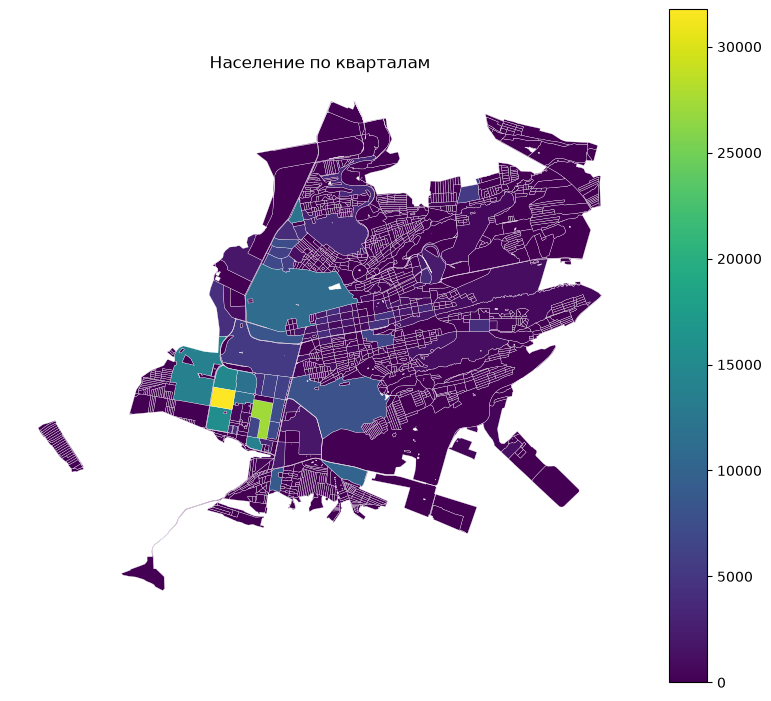

In [14]:
# ============================================================
# 6. ЗДАНИЯ И НАСЕЛЕНИЕ
# ============================================================

from blocksnet.preprocessing.imputing import impute_buildings
from blocksnet.blocks.aggregation import aggregate_objects

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
buildings = load_geojson(RAW_DIR / "buildings_clean.geojson")
if buildings["is_living"].dtype != bool:
    buildings["is_living"] = (
        buildings["is_living"].astype(str).str.lower().isin(["true", "1", "1.0"])
    )
buildings["number_of_floors"] = pd.to_numeric(
    buildings["number_of_floors"], errors="coerce"
)

buildings = impute_buildings(
    buildings,
    default_number_of_floors=1,
    living_area_coefficient=0.9,
    default_living_demand=30,
)

buildings_blocks, excess_buildings = aggregate_objects(blocks, buildings)
save_geojson(
    buildings_blocks,
    PROCESSED_DIR / f"{territory_key}_buildings_blocks.geojson",
    with_block_id=True,
)

print()
print("Зданий:", len(buildings))
print(f"Население зданий до агрегации: {int(buildings['population'].sum()):,}".replace(",", " "))
print(f"Население (модельное): {int(buildings_blocks['population'].sum()):,}".replace(",", " "))
print(f"Жилая площадь: {buildings_blocks['living_area'].sum() / 1e6:.2f} млн м²")
print(f"Зданий вне кварталов: {len(excess_buildings)}")

print()
print("Как выглядят здания после заполнения пропусков (первые 5):")
display(buildings.head())

print()
print("Как выглядят кварталы с посчитанными зданиями (первые 5):")
display(buildings_blocks.head())

show_map(
    buildings_blocks,
    column="population",
    title="Население по кварталам",
    path=RESULTS_DIR / f"{territory_key}_population_map.png",
)

## 7. Школы

- Берём школы из OSM (`amenity=school`).
- Если вместимость не указана, `impute_services` ставит минимальную из конфига BlocksNet — 250 мест.
- Привязываем школы к кварталам.

**Допущение:** вместимость школ в OSM почти всегда отсутствует, поэтому 250 мест — модельная
величина. В выводах это нужно указывать.

Результат: `data_stavropol/processed/<территория>_schools_blocks.geojson`.

2026-10-31 15:04:46.604 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-31 15:04:46.606 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


💾 Сохранено: city_schools_blocks.geojson — 1846 объектов

Школ: 80
Школьных мест (модельно): 21000
Школ вне кварталов: 0

Как выглядят школы после заполнения вместимости (первые 5):


,geometry,capacity
0,POINT (735093.832 4992772.315),250.0
1,POINT (732409.103 4991168.213),250.0
2,POINT (731933.313 4991269.511),250.0
3,POINT (730860.915 4990895.122),250.0
4,POINT (730025.046 4988029.986),250.0



Как выглядят кварталы с посчитанными школами (первые 5):


,geometry,capacity,count
0,"POLYGON ((735803.344 4993925.52, 735803.507 49...",0.0,0.0
1,"POLYGON ((735805.465 4993968.093, 735804.611 4...",0.0,0.0
2,"POLYGON ((735805.465 4993968.093, 735805.328 4...",0.0,0.0
3,"POLYGON ((735805.328 4993972.226, 735805.465 4...",0.0,0.0
4,"POLYGON ((735805.328 4993972.226, 735808.21 49...",0.0,0.0


🖼️ Сохранена карта: city_schools_map.png


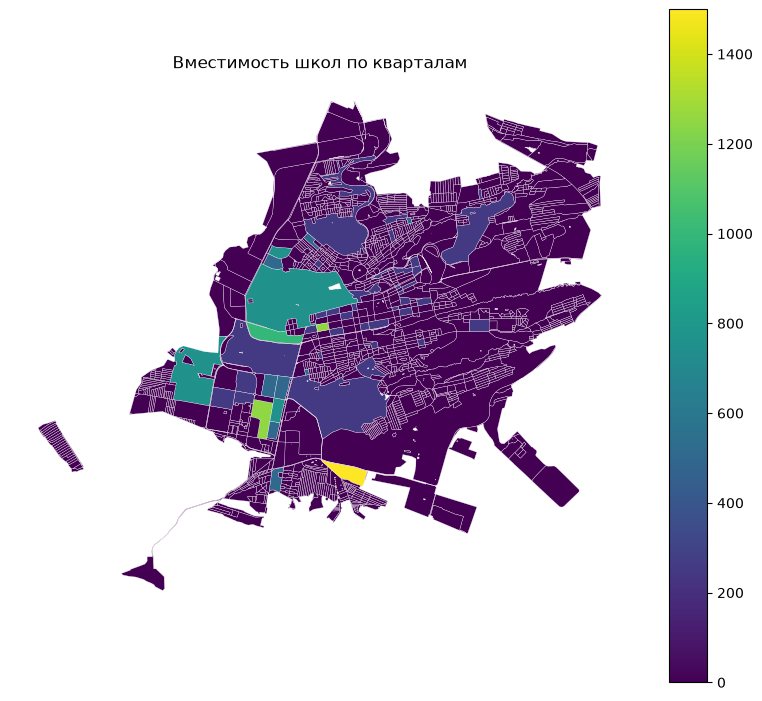

In [15]:
# ============================================================
# 7. ШКОЛЫ
# ============================================================

from blocksnet.preprocessing.imputing import impute_services

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
schools = load_geojson(RAW_DIR / "schools_clean.geojson")

if len(schools) == 0:
    raise RuntimeError("Нет школ. Проверьте файл schools_clean.geojson.")

schools = impute_services(schools, "school")
schools_blocks, excess_schools = aggregate_objects(blocks, schools)
save_geojson(
    schools_blocks,
    PROCESSED_DIR / f"{territory_key}_schools_blocks.geojson",
    with_block_id=True,
)

print()
print("Школ:", len(schools))
print("Школьных мест (модельно):", int(schools_blocks["capacity"].sum()))
print("Школ вне кварталов:", len(excess_schools))

print()
print("Как выглядят школы после заполнения вместимости (первые 5):")
display(schools.head())

print()
print("Как выглядят кварталы с посчитанными школами (первые 5):")
display(schools_blocks.head())

show_map(
    schools_blocks,
    column="capacity",
    title="Вместимость школ по кварталам",
    path=RESULTS_DIR / f"{territory_key}_schools_map.png",
)

## 8. Обеспеченность школами

`competitive_provision` распределяет спрос на школы между кварталами с учётом времени в пути.

Норматив берётся из конфига BlocksNet:

- 120 мест на 1000 жителей;
- доступность 15 минут.

**Как читать результат:**

- `provision_strong` — какая доля спроса закрыта местами **в пределах 15 минут**;
- `provision_weak` — какая доля спроса закрыта местами **за любое время** (в том числе далеко).

Это доли спроса, а не доли кварталов. Значение `1.0` — спрос закрыт полностью,
`0.0` — не закрыт, пусто — в квартале нет жителей.

Результаты: `*_provision.csv`, `*_provision_links.csv`, карта.

2026-10-31 15:04:47.865 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-31 15:04:47.865 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-31 15:04:47.875 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-31 15:04:47.892 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-31 15:04:48.319 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished



Норматив: 120 мест на 1000 жителей; доступность 15 минут.
Сильная обеспеченность: 34.9%
Слабая обеспеченность: 34.9%
Это доля удовлетворённого спроса, а не доля кварталов.

Входные данные: население кварталов и вместимость школ (первые 5):


,population,capacity
0,2284.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0



Результат по кварталам (первые 5):


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,275,0,275,0,0,0,0,0,0.0,0.0
1,0,0,0,0,0,0,0,0,NaN,NaN
2,0,0,0,0,0,0,0,0,NaN,NaN
3,0,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,0,NaN,NaN



Связи «квартал → школа»: сколько учеников прикреплено (первые 5):


value
source target       
7      15        5.0
16     17      166.0
       89       63.0
18     15       85.0
34     41       11.0

🖼️ Сохранена карта: city_provision_map.png


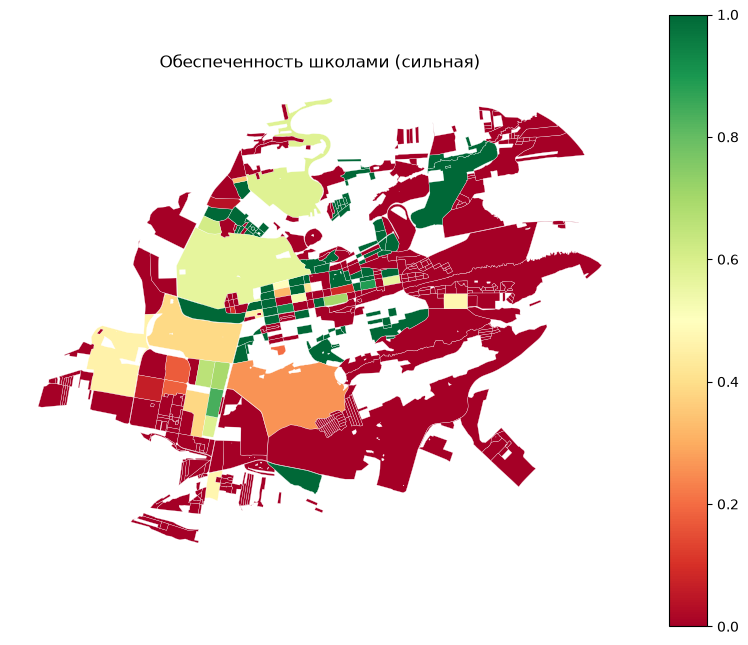

In [16]:
# ============================================================
# 8. ОБЕСПЕЧЕННОСТЬ ШКОЛАМИ
# ============================================================

from blocksnet.config import service_types_config
from blocksnet.analysis.provision import (
    competitive_provision,
    provision_strong_total,
    provision_weak_total,
)

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
buildings_blocks = load_geojson(
    PROCESSED_DIR / f"{territory_key}_buildings_blocks.geojson", as_blocks=True
)
schools_blocks = load_geojson(
    PROCESSED_DIR / f"{territory_key}_schools_blocks.geojson", as_blocks=True
)
acc_mx = pd.read_parquet(RESULTS_DIR / f"{territory_key}_accessibility_matrix.parquet")

school_cfg = service_types_config["school"]
demand_per_1000 = int(school_cfg["demand"])
accessibility_min = int(school_cfg["accessibility"])

prov_input = buildings_blocks[["population"]].join(schools_blocks[["capacity"]], how="left")
prov_input["capacity"] = prov_input["capacity"].fillna(0)

prov_df, links_df = competitive_provision(
    prov_input,
    acc_mx,
    accessibility=accessibility_min,
    demand=demand_per_1000,
)

prov_df.to_csv(RESULTS_DIR / f"{territory_key}_provision.csv", index_label="block_id")
links_df.to_csv(RESULTS_DIR / f"{territory_key}_provision_links.csv")

print()
print(f"Норматив: {demand_per_1000} мест на 1000 жителей; доступность {accessibility_min} минут.")
print(f"Сильная обеспеченность: {provision_strong_total(prov_df):.1%}")
print(f"Слабая обеспеченность: {provision_weak_total(prov_df):.1%}")
print("Это доля удовлетворённого спроса, а не доля кварталов.")

print()
print("Входные данные: население кварталов и вместимость школ (первые 5):")
display(prov_input.head())

print()
print("Результат по кварталам (первые 5):")
display(prov_df.head())

print()
print("Связи «квартал → школа»: сколько учеников прикреплено (первые 5):")
display(links_df.head())

show_map(
    blocks.join(prov_df["provision_strong"]),
    column="provision_strong",
    title="Обеспеченность школами (сильная)",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    path=RESULTS_DIR / f"{territory_key}_provision_map.png",
)

## 9. Плотностные показатели

`calculate_density_indicators` считает:

- `fsi` — коэффициент плотности застройки (площадь этажей / площадь квартала);
- `gsi` — доля застроенной площади;
- `mxi` — доля жилой площади в общей площади застройки;
- `l` — средняя этажность;
- `osr` — обеспеченность открытыми пространствами;
- `share_living`, `share_non_living` — доли жилой и нежилой площади.

Пустые кварталы без зданий дают `NaN` или `inf` — это нормально, в статистике они учитываются отдельно.

Результат: `data_stavropol/processed/<территория>_density.csv`.


Кварталов с застройкой: 1306 из 1846
  медиана fsi: 0.129
  медиана gsi: 0.127
  медиана mxi: 0.000
  медиана l: 1.000
  медиана osr: 6.758

Плотностные показатели по кварталам (первые 5):


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,832190.537156,233091.928322,305087.612162,68729.930651,236357.681510,0.366608,0.280094,0.225279,1.308872,1.963694,0.294862,1.014011
1,21952.267226,1045.928894,1045.928894,0.000000,1045.928894,0.047646,0.047646,0.000000,1.000000,19.988298,0.000000,1.000000
2,1565.126801,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
3,1274.690622,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
4,17335.385506,3262.105204,3904.726787,0.000000,3904.726787,0.225246,0.188176,0.000000,1.196996,3.604165,0.000000,1.196996


🖼️ Сохранена карта: city_fsi_map.png


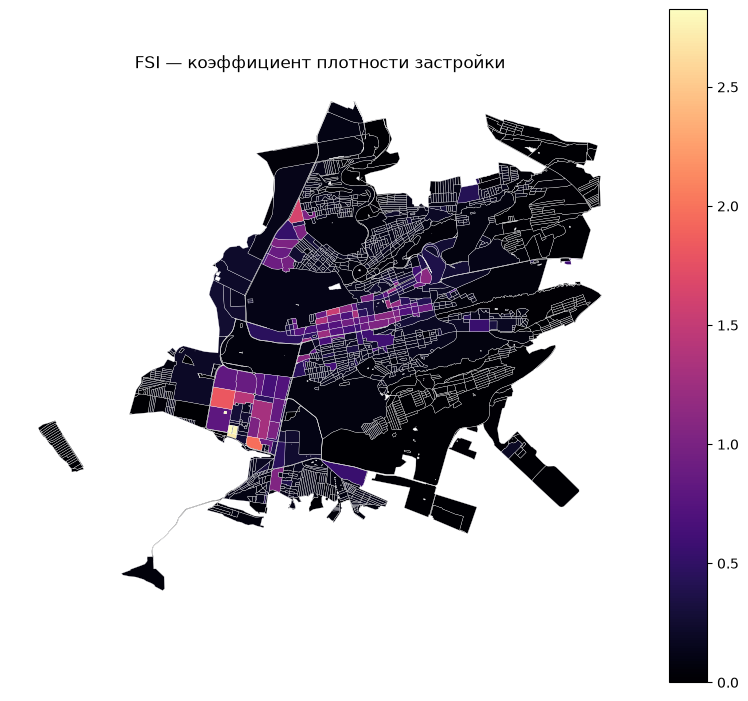

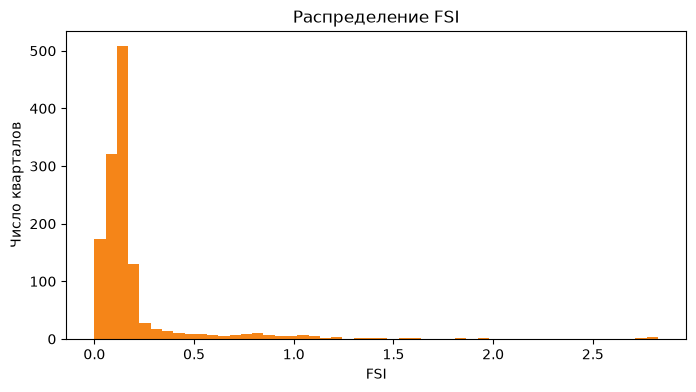

In [17]:
# ============================================================
# 9. ПЛОТНОСТНЫЕ ПОКАЗАТЕЛИ
# ============================================================

from blocksnet.analysis.indicators import calculate_density_indicators

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
buildings_blocks = load_geojson(
    PROCESSED_DIR / f"{territory_key}_buildings_blocks.geojson", as_blocks=True
)

buildings_blocks["site_area"] = blocks["site_area"]
density_df = calculate_density_indicators(buildings_blocks)
density_df.to_csv(PROCESSED_DIR / f"{territory_key}_density.csv", index_label="block_id")

developed = density_df[density_df["fsi"] > 0]
print()
print("Кварталов с застройкой:", len(developed), "из", len(density_df))
for col in ["fsi", "gsi", "mxi", "l", "osr"]:
    if col in developed.columns:
        print(f"  медиана {col}: {developed[col].median():.3f}")

print()
print("Плотностные показатели по кварталам (первые 5):")
display(density_df.head())

show_map(
    blocks.join(density_df["fsi"]),
    column="fsi",
    title="FSI — коэффициент плотности застройки",
    cmap="magma",
    path=RESULTS_DIR / f"{territory_key}_fsi_map.png",
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(developed["fsi"].dropna(), bins=50, color="#f58518")
ax.set_xlabel("FSI")
ax.set_ylabel("Число кварталов")
ax.set_title("Распределение FSI")
fig.savefig(RESULTS_DIR / f"{territory_key}_fsi_hist.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Морфотипы застройки

- **Spacematrix** — кластеризация кварталов по плотности, этажности и доле жилья
  (11 кластеров, `random_state=42`).
- **Strelka** — правила, которые переводят `l`, `fsi`, `mxi` в понятные типы:
  индивидуальная застройка, среднеэтажная, советский микрорайон и т.д.

Кластеризуются только кварталы с застройкой (`fsi > 0`). Пустые кварталы остаются без типа.

Результаты: `*_spacematrix.csv`, `*_strelka.csv`, карты.


Морфотипы Spacematrix:
spacematrix_morphotype
low-rise low-density non-residential      972
NaN                                       540
low-rise low-density residential          154
low-rise low-density mixed-use             94
mid-rise residential                       29
mid-rise low-density residential           28
mid-rise low-density mixed-use             18
high-mid-rise residential                   7
high-mid-rise high-density residential      3
tower high-density non-residential          1

Морфотипы Strelka:
strelka_morphotype
low-rise non-residential          901
NaN                               540
low-rise model                    256
individual residential            100
mid-rise                           37
high-rise modern microdistrict      4
mid-rise block                      3
central model                       3
high-rise non-residential           1
mid-rise non-residential            1

Spacematrix: квартал → кластер и тип застройки (первые 5):


,l,fsi,mxi,cluster,morphotype
0,1.308872,0.366608,0.225279,8.0,low-rise low-density non-residential
1,1.000000,0.047646,0.000000,0.0,low-rise low-density non-residential
2,0.000000,0.000000,0.000000,NaN,NaN
3,0.000000,0.000000,0.000000,NaN,NaN
4,1.196996,0.225246,0.000000,0.0,low-rise low-density non-residential



Spacematrix: описание кластеров и медианы l / fsi / mxi:


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.119970,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
1,3.024423,0.763844,0.251086,mid-rise,low-density,mixed-use,mid-rise low-density mixed-use
2,1.000000,0.134311,0.821040,low-rise,low-density,residential,low-rise low-density residential
3,9.363059,2.792652,0.899284,high-mid-rise,high-density,residential,high-mid-rise high-density residential
4,7.151436,1.542209,0.821703,high-mid-rise,None,residential,high-mid-rise residential
5,4.939774,1.019998,0.742157,mid-rise,None,residential,mid-rise residential
6,2.195612,0.392682,0.554515,low-rise,low-density,residential,low-rise low-density residential
7,1.000000,0.114666,0.380877,low-rise,low-density,mixed-use,low-rise low-density mixed-use
8,1.472849,0.332618,0.023037,low-rise,low-density,non-residential,low-rise low-density non-residential



Strelka: квартал → тип застройки (первые 5):


,l,fsi,mxi,morphotype
0,1.308872,0.366608,0.225279,low-rise model
1,1.000000,0.047646,0.000000,low-rise non-residential
2,0.000000,0.000000,0.000000,NaN
3,0.000000,0.000000,0.000000,NaN
4,1.196996,0.225246,0.000000,low-rise non-residential


🖼️ Сохранена карта: city_spacematrix_map.png


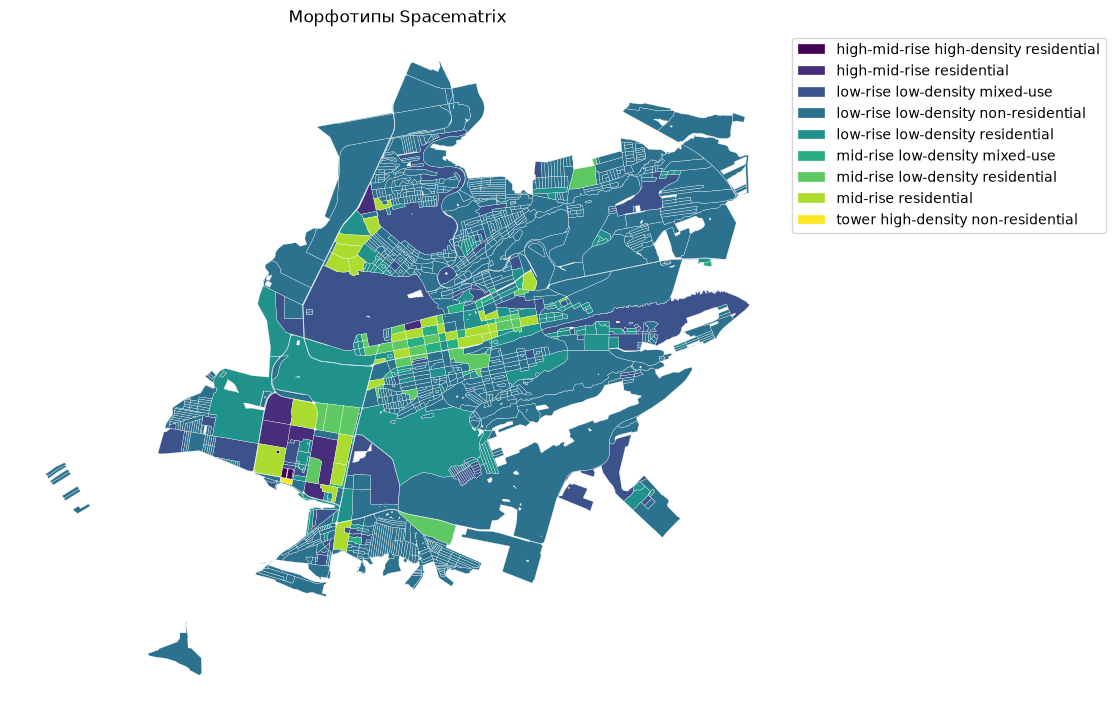

🖼️ Сохранена карта: city_strelka_map.png


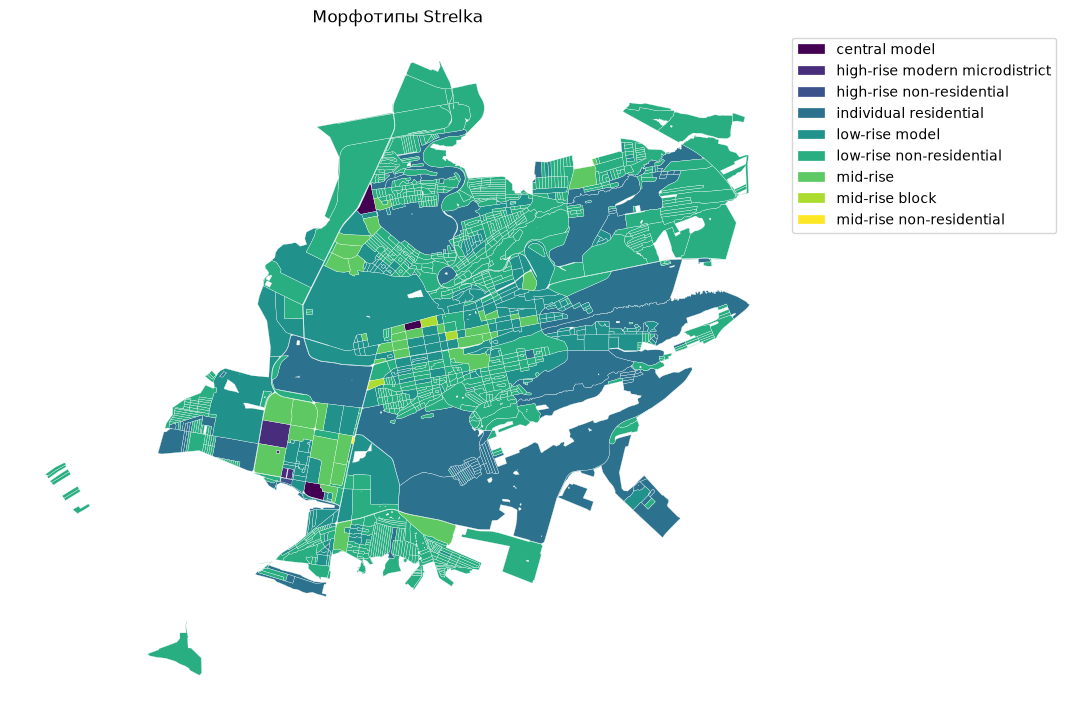

In [18]:
# ============================================================
# 10. МОРФОТИПЫ
# ============================================================

from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
density_df = pd.read_csv(PROCESSED_DIR / f"{territory_key}_density.csv", index_col=0)

n_developed = int((density_df["fsi"] > 0).sum())
if n_developed >= 2:
    n_clusters = min(11, n_developed)
    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(
        density_df,
        n_clusters=n_clusters,
        random_state=42,
    )
else:
    spacematrix_df = pd.DataFrame(index=density_df.index)
    spacematrix_df["cluster"] = None
    spacematrix_df["morphotype"] = None
    spacematrix_clusters = pd.DataFrame()

strelka_df = get_strelka_morphotypes(density_df)

spacematrix_out = spacematrix_df[["cluster", "morphotype"]].rename(
    columns={"morphotype": "spacematrix_morphotype"}
)
strelka_out = strelka_df[["morphotype"]].rename(
    columns={"morphotype": "strelka_morphotype"}
)

spacematrix_out.to_csv(
    PROCESSED_DIR / f"{territory_key}_spacematrix.csv", index_label="block_id"
)
strelka_out.to_csv(
    PROCESSED_DIR / f"{territory_key}_strelka.csv", index_label="block_id"
)
if len(spacematrix_clusters):
    spacematrix_clusters.to_csv(PROCESSED_DIR / f"{territory_key}_spacematrix_clusters.csv")

print()
print("Морфотипы Spacematrix:")
print(spacematrix_out["spacematrix_morphotype"].value_counts(dropna=False).to_string())
print()
print("Морфотипы Strelka:")
print(strelka_out["strelka_morphotype"].value_counts(dropna=False).to_string())

print()
print("Spacematrix: квартал → кластер и тип застройки (первые 5):")
display(spacematrix_df.head())

if len(spacematrix_clusters):
    print()
    print("Spacematrix: описание кластеров и медианы l / fsi / mxi:")
    display(spacematrix_clusters)

print()
print("Strelka: квартал → тип застройки (первые 5):")
display(strelka_df.head())

show_map(
    blocks.join(spacematrix_out["spacematrix_morphotype"]),
    column="spacematrix_morphotype",
    title="Морфотипы Spacematrix",
    categorical=True,
    path=RESULTS_DIR / f"{territory_key}_spacematrix_map.png",
)
show_map(
    blocks.join(strelka_out["strelka_morphotype"]),
    column="strelka_morphotype",
    title="Морфотипы Strelka",
    categorical=True,
    path=RESULTS_DIR / f"{territory_key}_strelka_map.png",
)

## 11. Доступность территории

`area_accessibility` считает средневзвешенное время доступности: чем больше площадь квартала,
тем больший вклад он вносит. Считаем два варианта:

- `area_accessibility_raw` — как в библиотеке, `inf` остаётся `inf`;
- `area_accessibility_cap60` — недостижимые пары заменены на 60 минут, чтобы можно было
  строить карту и сравнивать районы.

Результат: `data_stavropol/results/<территория>_area_accessibility.csv`.


Медиана доступности (без ограничения): 106.1 мин
Медиана доступности (inf заменён на 60 мин): 106.1 мин
🖼️ Сохранена карта: city_area_accessibility_map.png


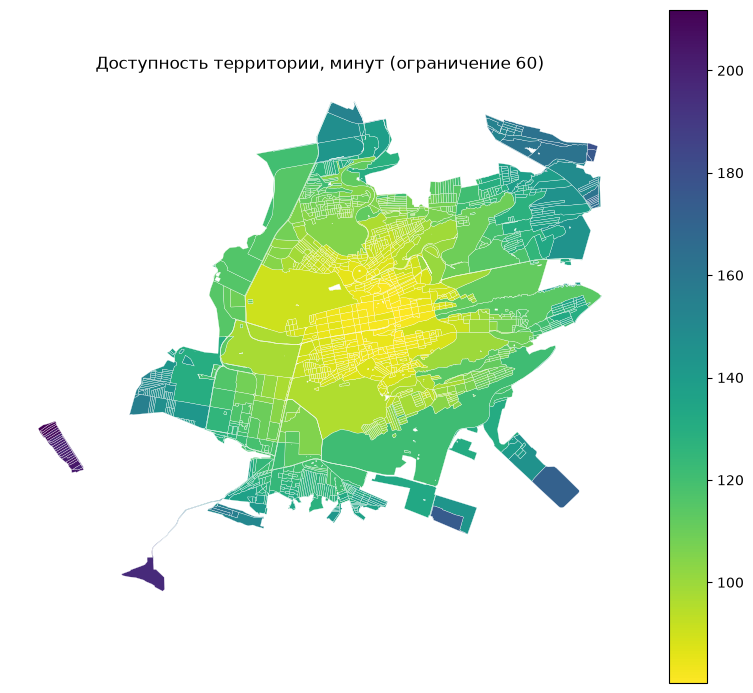

In [19]:
# ============================================================
# 11. ДОСТУПНОСТЬ ТЕРРИТОРИИ
# ============================================================

from blocksnet.analysis.network.accessibility.area import area_accessibility

territory_key, _, _ = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
acc_mx = pd.read_parquet(RESULTS_DIR / f"{territory_key}_accessibility_matrix.parquet")

area_blocks = blocks[["site_area"]].copy()
area_raw = area_accessibility(acc_mx, area_blocks, out=True)
area_raw = area_raw.rename(columns={"area_accessibility": "area_accessibility_raw"})

acc_capped = acc_mx.replace([np.inf], 60)
area_capped = area_accessibility(acc_capped, area_blocks, out=True)
area_capped = area_capped.rename(columns={"area_accessibility": "area_accessibility_cap60"})

area_df = area_raw.join(area_capped)
area_df.to_csv(
    RESULTS_DIR / f"{territory_key}_area_accessibility.csv", index_label="block_id"
)

print()
print(
    "Медиана доступности (без ограничения): "
    f"{area_raw['area_accessibility_raw'].replace([np.inf], np.nan).median():.1f} мин"
)
print(
    "Медиана доступности (inf заменён на 60 мин): "
    f"{area_capped['area_accessibility_cap60'].median():.1f} мин"
)

show_map(
    blocks.join(area_capped["area_accessibility_cap60"]),
    column="area_accessibility_cap60",
    title="Доступность территории, минут (ограничение 60)",
    cmap="viridis_r",
    path=RESULTS_DIR / f"{territory_key}_area_accessibility_map.png",
)

## 12. Итоговая таблица и карты

Собираем все показатели в один слой и одну таблицу:

- `data_stavropol/results/<территория>_blocks_final.geojson` — кварталы со всеми атрибутами;
- `data_stavropol/results/<территория>_metrics.csv` — таблица без геометрии.

Эти файлы потом будет читать HTML-дашборд, поэтому их не нужно пересоздавать вручную.

В таблице будут и `spacematrix_cluster` (номер кластера), и оба морфотипа — Spacematrix
и Strelka, — чтобы можно было сравнить два взгляда на тип застройки.

In [20]:
# ============================================================
# 12. ИТОГОВАЯ ТАБЛИЦА
# ============================================================

territory_key, _, territory_meta = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
land_use = load_geojson(PROCESSED_DIR / f"{territory_key}_land_use.geojson", as_blocks=True)
buildings_blocks = load_geojson(
    PROCESSED_DIR / f"{territory_key}_buildings_blocks.geojson", as_blocks=True
)
schools_blocks = load_geojson(
    PROCESSED_DIR / f"{territory_key}_schools_blocks.geojson", as_blocks=True
)

density_df = pd.read_csv(PROCESSED_DIR / f"{territory_key}_density.csv", index_col=0)
spacematrix_df = pd.read_csv(PROCESSED_DIR / f"{territory_key}_spacematrix.csv", index_col=0)
strelka_df = pd.read_csv(PROCESSED_DIR / f"{territory_key}_strelka.csv", index_col=0)
prov_df = pd.read_csv(RESULTS_DIR / f"{territory_key}_provision.csv", index_col=0)
area_df = pd.read_csv(RESULTS_DIR / f"{territory_key}_area_accessibility.csv", index_col=0)

final = blocks.copy()
final = final.join(land_use[["land_use", "share"]], how="left")
final = final.join(
    buildings_blocks[
        [
            "population",
            "footprint_area",
            "build_floor_area",
            "living_area",
            "non_living_area",
            "count",
        ]
    ].rename(columns={"count": "building_count"}),
    how="left",
)
final = final.join(
    schools_blocks[["capacity", "count"]].rename(
        columns={"capacity": "school_capacity", "count": "school_count"}
    ),
    how="left",
)
final = final.join(prov_df[["demand", "provision_strong", "provision_weak"]], how="left")
final = final.join(
    density_df[["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]],
    how="left",
)
final = final.join(
    spacematrix_df[["cluster", "spacematrix_morphotype"]].rename(
        columns={"cluster": "spacematrix_cluster"}
    ),
    how="left",
)
final = final.join(strelka_df[["strelka_morphotype"]], how="left")
final = final.join(
    area_df[["area_accessibility_raw", "area_accessibility_cap60"]], how="left"
)

final["area_ha"] = final["site_area"] / 10000

save_geojson(
    final,
    RESULTS_DIR / f"{territory_key}_blocks_final.geojson",
    with_block_id=True,
)
final.drop(columns="geometry").to_csv(
    RESULTS_DIR / f"{territory_key}_metrics.csv", index_label="block_id"
)

print()
print("Территория:", territory_meta["territory_name"])
print("Кварталов в итоговой таблице:", len(final))
print("Колонки:")
print(", ".join(final.drop(columns="geometry").columns))
final.head()

💾 Сохранено: city_blocks_final.geojson — 1846 объектов

Территория: весь город Ставрополь
Кварталов в итоговой таблице: 1846
Колонки:
site_area, land_use, share, population, footprint_area, build_floor_area, living_area, non_living_area, building_count, school_capacity, school_count, demand, provision_strong, provision_weak, fsi, gsi, mxi, l, osr, share_living, share_non_living, spacematrix_cluster, spacematrix_morphotype, strelka_morphotype, area_accessibility_raw, area_accessibility_cap60, area_ha


,site_area,geometry,land_use,share,population,footprint_area,build_floor_area,living_area,non_living_area,building_count,school_capacity,school_count,demand,provision_strong,provision_weak,fsi,gsi,mxi,l,osr,share_living,share_non_living,spacematrix_cluster,spacematrix_morphotype,strelka_morphotype,area_accessibility_raw,area_accessibility_cap60,area_ha
0,832190.537156,"POLYGON ((735803.344 4993925.52, 735803.507 49...",industrial,0.622465,2284.0,233091.928322,305087.612162,68729.930651,236357.681510,373.0,0.0,0.0,275,0.0,0.0,0.366608,0.280094,0.225279,1.308872,1.963694,0.294862,1.014011,8.0,low-rise low-density non-residential,low-rise model,100.825875,100.825875,83.219054
1,21952.267226,"POLYGON ((735805.465 4993968.093, 735804.611 4...",residential,0.499727,0.0,1045.928894,1045.928894,0.000000,1045.928894,11.0,0.0,0.0,0,NaN,NaN,0.047646,0.047646,0.000000,1.000000,19.988298,0.000000,1.000000,0.0,low-rise low-density non-residential,low-rise non-residential,89.761774,89.761774,2.195227
2,1565.126801,"POLYGON ((735805.465 4993968.093, 735805.328 4...",transport,0.537054,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,NaN,NaN,0.000000,0.000000,NaN,NaN,inf,NaN,NaN,NaN,NaN,NaN,92.431168,92.431168,0.156513
3,1274.690622,"POLYGON ((735805.328 4993972.226, 735805.465 4...",None,NaN,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0,NaN,NaN,0.000000,0.000000,NaN,NaN,inf,NaN,NaN,NaN,NaN,NaN,90.448926,90.448926,0.127469
4,17335.385506,"POLYGON ((735805.328 4993972.226, 735808.21 49...",industrial,0.782399,0.0,3262.105204,3904.726787,0.000000,3904.726787,12.0,0.0,0.0,0,NaN,NaN,0.225246,0.188176,0.000000,1.196996,3.604165,0.000000,1.196996,0.0,low-rise low-density non-residential,low-rise non-residential,91.282480,91.282480,1.733539


🖼️ Сохранена карта: city_final_population.png


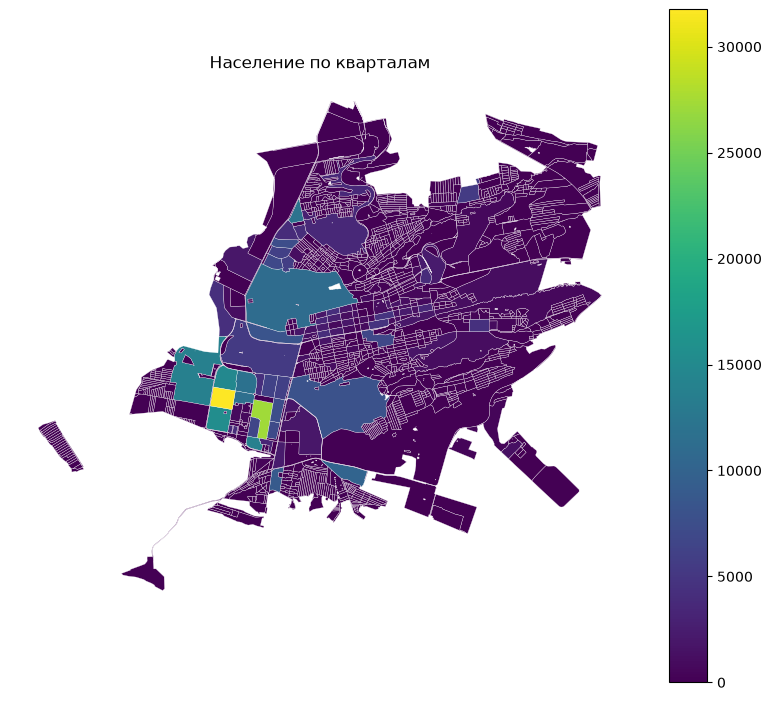

🖼️ Сохранена карта: city_final_provision.png


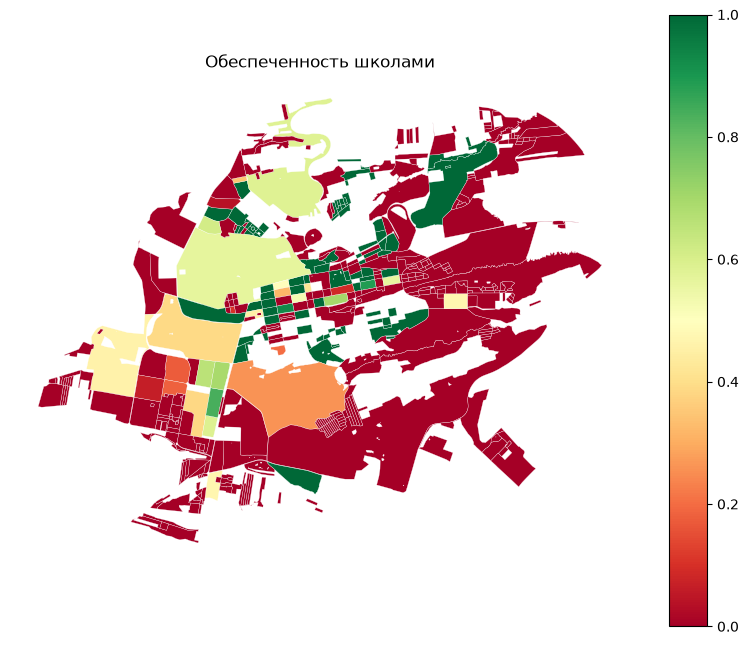

🖼️ Сохранена карта: city_final_fsi.png


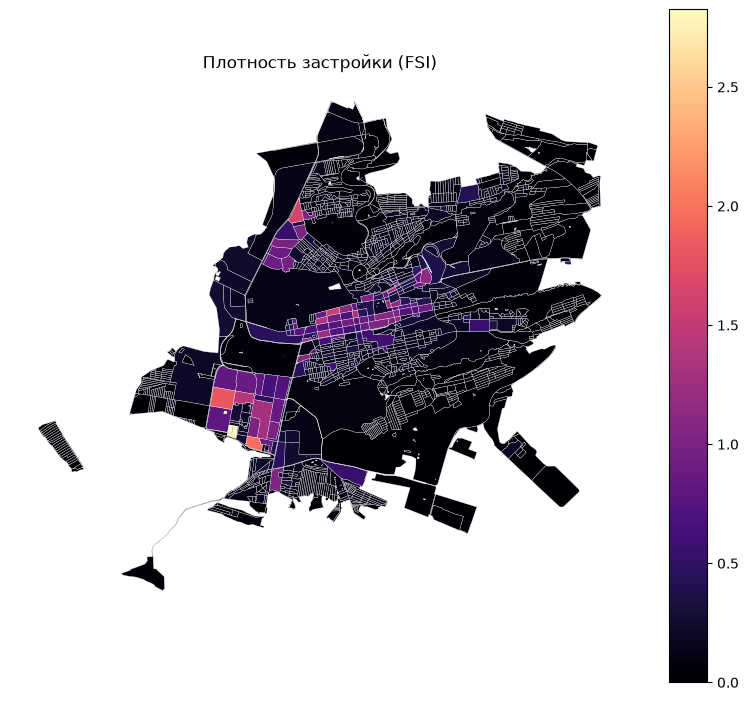

🖼️ Сохранена карта: city_final_morphotypes.png


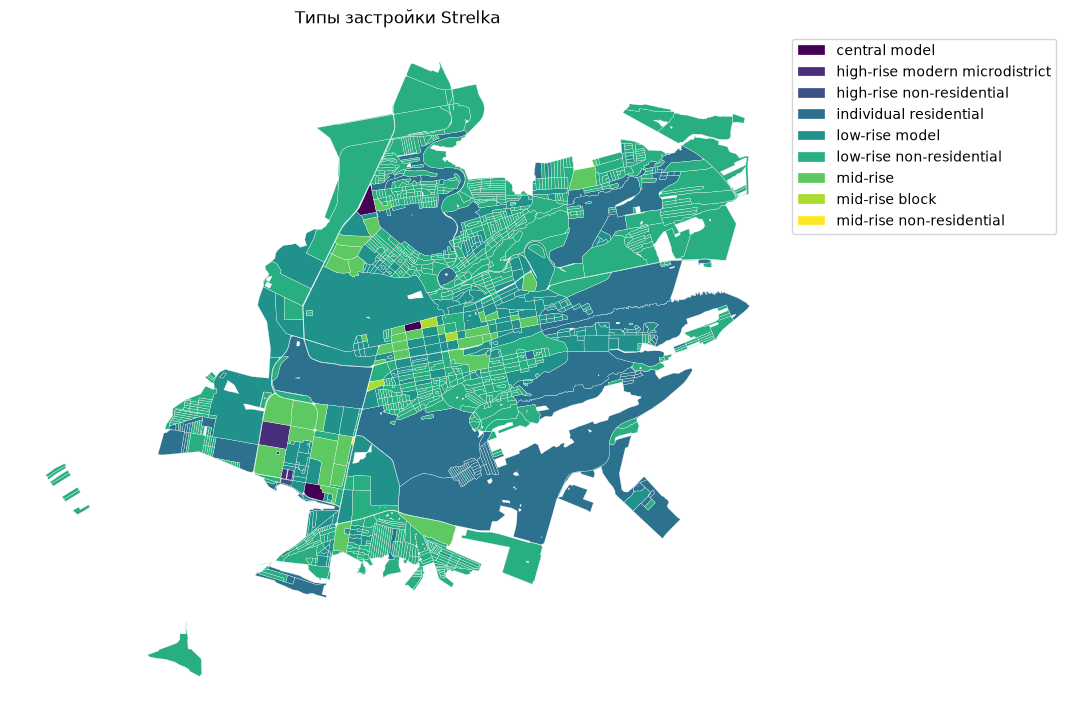

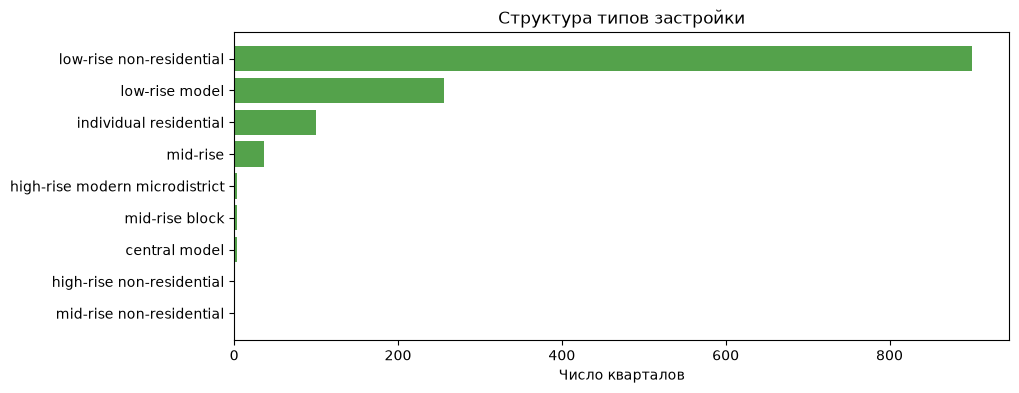

In [21]:
# Итоговые карты и графики
territory_key, _, _ = get_territory()
final = load_geojson(RESULTS_DIR / f"{territory_key}_blocks_final.geojson", as_blocks=True)

show_map(
    final,
    column="population",
    title="Население по кварталам",
    path=RESULTS_DIR / f"{territory_key}_final_population.png",
)
show_map(
    final,
    column="provision_strong",
    title="Обеспеченность школами",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    path=RESULTS_DIR / f"{territory_key}_final_provision.png",
)
show_map(
    final,
    column="fsi",
    title="Плотность застройки (FSI)",
    cmap="magma",
    path=RESULTS_DIR / f"{territory_key}_final_fsi.png",
)
show_map(
    final,
    column="strelka_morphotype",
    title="Типы застройки Strelka",
    categorical=True,
    path=RESULTS_DIR / f"{territory_key}_final_morphotypes.png",
)

fig, ax = plt.subplots(figsize=(10, 4))
counts = final["strelka_morphotype"].value_counts()
ax.barh(counts.index[::-1], counts.values[::-1], color="#54a24b")
ax.set_xlabel("Число кварталов")
ax.set_title("Структура типов застройки")
fig.savefig(
    RESULTS_DIR / f"{territory_key}_morphotypes_bar.png", dpi=150, bbox_inches="tight"
)
plt.show()

## 13. Проверка результатов

Проверяем самые важные вещи:

- кварталы в метрической системе координат;
- геометрии непустые, площади положительные;
- матрица совпадает с кварталами по номерам;
- в матрице нет `NaN`;
- население и школы посчитаны;
- типы застройки и доступность не пустые.

Если какой-то пункт отмечен ❌ — не делайте выводы, сначала напишите мне.

In [22]:
# ============================================================
# 13. ПРОВЕРКА РЕЗУЛЬТАТОВ
# ============================================================

territory_key, _, territory_meta = get_territory()
blocks = load_geojson(PROCESSED_DIR / f"{territory_key}_blocks.geojson", as_blocks=True)
final = load_geojson(RESULTS_DIR / f"{territory_key}_blocks_final.geojson", as_blocks=True)
acc_mx = pd.read_parquet(RESULTS_DIR / f"{territory_key}_accessibility_matrix.parquet")

checks = {
    "Кварталы в метрической CRS EPSG:32637": blocks.crs.to_epsg() == 32637,
    "Все геометрии кварталов непустые": bool(
        blocks.geometry.notna().all() and (~blocks.geometry.is_empty).all()
    ),
    "Площади кварталов положительные": bool((blocks["site_area"] > 0).all()),
    "Индексы матрицы совпадают с кварталами": bool(
        set(acc_mx.index) == set(blocks.index)
        and set(acc_mx.columns) == set(blocks.index)
    ),
    "В матрице нет NaN": not bool(acc_mx.isna().any().any()),
    "Население посчитано": float(final["population"].sum()) > 0,
    "Школы найдены": float(final["school_count"].sum()) > 0,
    "Есть типы застройки": bool(final["strelka_morphotype"].notna().any()),
    "Есть доступность территории": bool(
        np.isfinite(final["area_accessibility_cap60"]).any()
    ),
}

print("ПРОВЕРКА РЕЗУЛЬТАТОВ")
print("=" * 60)
for name, ok in checks.items():
    print(("✅" if ok else "❌"), name)

if all(checks.values()):
    print()
    print("✅ Все базовые проверки пройдены.")
else:
    print()
    print("⚠️ Есть неудачные проверки. Посмотрите пояснение в ноутбуке и напишите мне.")

summary = pd.DataFrame(
    {
        "Показатель": [
            "Территория",
            "Кварталов",
            "Площадь, км²",
            "Население (модельное)",
            "Школ",
            "Школьных мест",
            "Медиана FSI (застроенные)",
            "Медиана доступности, мин (cap 60)",
        ],
        "Значение": [
            territory_meta["territory_name"],
            len(final),
            round(final["site_area"].sum() / 1e6, 1),
            int(final["population"].sum()),
            int(final["school_count"].sum()),
            int(final["school_capacity"].sum()),
            round(final.loc[final["fsi"] > 0, "fsi"].median(), 2),
            round(final["area_accessibility_cap60"].median(), 1),
        ],
    }
)
display(summary)

ПРОВЕРКА РЕЗУЛЬТАТОВ
✅ Кварталы в метрической CRS EPSG:32637
✅ Все геометрии кварталов непустые
✅ Площади кварталов положительные
✅ Индексы матрицы совпадают с кварталами
✅ В матрице нет NaN
✅ Население посчитано
✅ Школы найдены
✅ Есть типы застройки
✅ Есть доступность территории

✅ Все базовые проверки пройдены.


,Показатель,Значение
0,Территория,весь город Ставрополь
1,Кварталов,1846
2,"Площадь, км²",165.2
3,Население (модельное),446545
4,Школ,80
5,Школьных мест,21000
6,Медиана FSI (застроенные),0.13
7,"Медиана доступности, мин (cap 60)",106.1


## 14. Повторный запуск и очистка кэша

### Обычный повторный запуск

1. Откройте ноутбук из корня проекта.
2. Выберите ядро `.venv_blocksnet`.
3. Запускайте ячейки по порядку или нажмите **Run All**.

Если `USE_CACHE = True`, уже скачанные данные и посчитанные файлы берутся с диска.
Повторно ничего не скачивается.

### Что удалить, чтобы пересчитать

Все команды выполняются в терминале VS Code из корня проекта.

```powershell
cd C:\Users\Влада\.vscode\python-package-boilerplate
```

**Заново скачать данные OpenStreetMap:**

```powershell
Remove-Item -Recurse -Force data_stavropol\raw
```

**Заново построить пешеходный граф (файл OSM 120 МБ останется на диске):**

```powershell
Remove-Item -Force data_stavropol\graph\*_walk_graph.pkl
Remove-Item -Force data_stavropol\graph\*_walk.osm
```

**Удалить и граф, и скачанный файл OSM (при следующем запуске скачается заново):**

```powershell
Remove-Item -Recurse -Force data_stavropol\graph
```

**Заново посчитать матрицу доступности:**

```powershell
Remove-Item -Force data_stavropol\results\*_accessibility_matrix.parquet
```

**Заново нарезать кварталы и посчитать показатели (данные OSM останутся):**

```powershell
Remove-Item -Recurse -Force data_stavropol\processed
Remove-Item -Recurse -Force data_stavropol\results
```

**Начать полностью с нуля:**

```powershell
Remove-Item -Recurse -Force data_stavropol
```

После удаления снова запустите ноутбук с начала.

### Как сменить территорию

В разделе 0 измените:

- `TERRITORY_MODE = "city"` — только город;
- `TERRITORY_MODE = "prom"` — только Промышленный район;
- `TERRITORY_MODE = "prom_south"` — южная половина района;
- `TERRITORY_MODE = "auto"` — автоматический выбор.

Затем удалите `data_stavropol\processed`, `data_stavropol\results` и `data_stavropol\graph`
(если меняете граф) и запустите разделы 3–13 заново. Файлы разных территорий
имеют разные префиксы и не перемешиваются.

### Если меняли `MAX_BLOCKS`

Измените значение в разделе 0, затем удалите `data_stavropol\graph`,
`data_stavropol\processed` и `data_stavropol\results` и перезапустите разделы 3–13.

## 15. Что дальше: HTML-дашборд

Следующим отдельным этапом сделаем Python-файл `make_dashboard.py`.
Он **не будет ничего пересчитывать**: возьмёт готовые файлы

- `data_stavropol/results/<территория>_blocks_final.geojson`,
- `data_stavropol/results/<территория>_metrics.csv`,
- `data_stavropol/results/<территория>_provision.csv`,
- `data_stavropol/results/<территория>_area_accessibility.csv`

и соберёт **одну HTML-страницу** с интерактивной картой, карточками показателей,
графиками, таблицами и выводами.

Запуск будет таким:

```powershell
cd C:\Users\Влада\.vscode\python-package-boilerplate
.\.venv_blocksnet\Scripts\python.exe make_dashboard.py
```

Результат: `dashboard_stavropol.html`, открывается двойным щелчком в браузере.

### Что прислать мне после запуска

1. Какая территория оказалась в работе (город, район или южная половина района).
2. Сколько кварталов, какое население и сколько школ получилось.
3. Какие проверки отмечены ❌.
4. Любые ошибки — скопируйте текст ошибки из ячейки.